In [293]:
import imageio
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl 
from tqdm import tqdm
from pathlib import Path

from util_KNMI_CAT_process import reservoir_Groningen

In [294]:
plt.rcParams.update({
    'axes.titlesize': 18,        # Main title
    'axes.labelsize': 14,        # Axis labels
    'xtick.labelsize': 14,       # X-axis tick labels
    'ytick.labelsize': 14,       # Y-axis tick labels
    'legend.fontsize': 14,       # Legend text
    'figure.titlesize': 18       # Figure-level suptitle
})

## seismic catalog

In [295]:
catalog = np.load('data/KNMI_CAT_1991-12to2023-01_mag_thickness_dpressure_date.npy', allow_pickle=True)

magnitude_all = catalog.item()["magnitude"]
date_all = catalog.item()["date"]
thickness_all = catalog.item()["thickness"]
dpressure_all = - catalog.item()["dpressure"]

In [296]:
Mc = 1.5
mask = magnitude_all >= Mc

magnitude_all = magnitude_all[mask]
date_all = date_all[mask]
thickness_all = thickness_all[mask]
dpressure_all = dpressure_all[mask]

print(f"Kept {mask.sum()} events with magnitude >= 1.5 (out of {len(mask)})")

Kept 326 events with magnitude >= 1.5 (out of 791)


In [297]:
# sort by date_all from small to large, and apply same order to other arrays
sort_idx = np.argsort(date_all)

date_all = date_all[sort_idx]
magnitude_all = magnitude_all[sort_idx]
thickness_all = thickness_all[sort_idx]
dpressure_all = dpressure_all[sort_idx]

print(f"Sorted ascending: {np.all(date_all[:-1] <= date_all[1:])}")
print(f"Range: {date_all[0]} -> {date_all[-1]}")

Sorted ascending: True
Range: 1991.9260748033996 -> 2023.0394770738203


## Pressure field 

In [298]:
print( date_all[ np.argmax( dpressure_all ) ], dpressure_all[ np.argmax( dpressure_all ) ] )
print( date_all[ np.argmin( date_all ) ], dpressure_all[ np.argmin( date_all ) ] ) 
print( date_all[ np.argmax( date_all ) ], dpressure_all[ np.argmax( date_all ) ] )

2016.2295593946064 27.823329491795405
1991.9260748033996 15.28877635390868
2023.0394770738203 25.802574688559844


In [299]:
reservoir = reservoir_Groningen()
df = reservoir.load_EQcatalog()
X, Y,THICKNESS = reservoir.load_thickness()
PRESSURE, DPRESSURE, MESH = reservoir.load_pressure_mesh() 

# DPRESSURE_grid_all = reservoir.interpolate_grid_DPRESSURE()
# np.savez("data_raw/dpressure_grid_all.npz", DPRESSURE_grid_all=DPRESSURE_grid_all)

DPRESSURE_grid_all = np.load("data/dpressure_grid_all.npz")['DPRESSURE_grid_all']

In [300]:
DPRESSURE_time = 1956 + 1/12 + np.arange(0,1000,1)/12
DPRESSURE_mean = np.mean(DPRESSURE, axis = 1)
dpressure_mean_all = - np.interp(date_all, DPRESSURE_time, DPRESSURE_mean)

print("dpressure mean in 1991", np.interp(1991, DPRESSURE_time, DPRESSURE_mean))
print("dpressure mean in 2012", np.interp(2012, DPRESSURE_time, DPRESSURE_mean))
print("dpressure mean in 2023", np.interp(2023, DPRESSURE_time, DPRESSURE_mean))
print("dpressure_mean_all max", np.max(dpressure_mean_all))

dpressure mean in 1991 -15.568691050376337
dpressure mean in 2012 -23.639979601649625
dpressure mean in 2023 -26.905551782837065
dpressure_mean_all max 26.90700136496288


In [301]:
idx_Huizinge = np.argmax(magnitude_all)

print("Huizinge event:", date_all[idx_Huizinge], magnitude_all[idx_Huizinge], dpressure_all[idx_Huizinge], thickness_all[idx_Huizinge])

Huizinge_DPRESSURE_mean = np.interp(date_all[idx_Huizinge], DPRESSURE_time, DPRESSURE_mean)

print("Huizinge Delta P (Flow2Quake):", dpressure_all[idx_Huizinge])

print("Huizinge Delta P (mean):", Huizinge_DPRESSURE_mean)


Huizinge event: 2012.6251718085916 3.6 23.054311899175204 268.9294
Huizinge Delta P (Flow2Quake): 23.054311899175204
Huizinge Delta P (mean): -24.017307691379052


## time and $\Delta P$

In [302]:
# parameter set for delta_P = 24 MPa, mu = 30 GPa, fd = 0.25
S1_Huizinge = 4e6 # 5e6
dip_Huizinge = 70 * np.pi / 180
B_Huizinge = 0.6687
beta_Huizinge = 6.0696 # 5.43
Kc = 7.1216e7 # Pa * m**0.5

mu = 30e9 #Pa
nu = 0.25

In [303]:
Sb_Huizinge = S1_Huizinge * (1 - B_Huizinge)

print("S_b = ", Sb_Huizinge * 1e-6, 'MPa')

Delta_S_Huizinge = S1_Huizinge * B_Huizinge

print("Delta_S = ", Delta_S_Huizinge * 1e-6, 'MPa')

C = - Delta_S_Huizinge * 1e-6 / Huizinge_DPRESSURE_mean

print("C = ", C)

S_b =  1.3252000000000002 MPa
Delta_S =  2.6748 MPa
C =  0.11136968532739047


In [304]:
version_scaling = 2

In [305]:
"""
-- Calculation of S1 -- 
"""
# version 1: contant B_Huizinge
if version_scaling == 1:
    # S1'/S1 = P1'/P1 S1 = 5MPa, P1 = 24MPa 
    S1_all = S1_Huizinge * dpressure_mean_all / (- Huizinge_DPRESSURE_mean)
    B_all = B_Huizinge * np.ones_like(S1_all)

# version 2: constant S0
if version_scaling == 2:
    Delta_S_Huizinge = S1_Huizinge * B_Huizinge
    S0_Huizinge  = S1_Huizinge - Delta_S_Huizinge

    DeltaS_all = Delta_S_Huizinge * (- dpressure_mean_all / Huizinge_DPRESSURE_mean)
    S1_all = S0_Huizinge + DeltaS_all
    B_all = DeltaS_all / S1_all

# Check
print("S_1 min", np.min(S1_all*1e-6), "max", np.max(S1_all*1e-6))
print("B min", np.min(B_all), "max", np.max(B_all))

S_1 min 3.1076209996751314 max 4.321824275119582
B min 0.5735644725857705 max 0.6933702261729896


In [306]:
data_phase = np.load('out/phase_diagram_ultralarge_datagrid.npy', allow_pickle=True).item() 


B_hat_grid = data_phase['T_grid']
Kc_hat_grid = data_phase['Kc_grid']
l_hat_grid = data_phase['l_grid']


Hi_synthetic_count = 1000

Hi = 10**(np.linspace(2.1, 2.9, Hi_synthetic_count) ) 

Kc_hat_all_allHi = np.full( [len(S1_all), Hi_synthetic_count], np.empty )

for idx in range( len(S1_all) ):
    S1 = S1_all[idx]
    Kc_hat_all_allHi[idx, :] = np.array( [ Kc / ( np.sqrt(np.pi/2) * S1 * np.sqrt(Hi / np.sin(dip_Huizinge))) ], dtype=float )

In [307]:
def locate_l_hat_on_grid(B_val, Kc_val):
    idx_B = (np.abs(B_hat_grid[:,0] - B_val)).argmin()
    idx_Kc = (np.abs(Kc_hat_grid[0,:] - Kc_val)).argmin()
    
    
    return l_hat_grid[idx_B, idx_Kc]

In [308]:
H_hat_all_allHi = np.full( [len(S1_all), Hi_synthetic_count], np.empty )

for idx in tqdm( range(len(S1_all)) ):
    Kc_allHi = Kc_hat_all_allHi[idx, :]
    H_hat_all_allHi[idx, :] = np.array(  [ locate_l_hat_on_grid(B_all[idx], Kc_Hi) for Kc_Hi in Kc_allHi ]  )

100%|██████████| 326/326 [00:03<00:00, 83.45it/s]


In [309]:
H_hat_all = np.full(len(date_all), np.nan)

for idx in range(len(date_all)):
    H_hat_EQ_allHi = np.float64(H_hat_all_allHi[idx,:])
    H_hat_all[idx] = np.interp(  thickness_all[idx], Hi, H_hat_EQ_allHi  )

W_all = thickness_all * H_hat_all / np.sin(dip_Huizinge)  

In [310]:
def G0(S1, W, mu):
    return 1/np.pi * (S1**2 * W) / (mu)

In [311]:
G0_all = G0(S1_all, W_all, mu)

In [312]:
G0_Huizinge = G0_all[idx_Huizinge]
Gc_Huizinge = Kc**2 * (1-nu) / (2*mu)

In [313]:
print("G0_Huizinge = ", G0_Huizinge * 1e-6, "MJ/m^2")
print("Gc_Huizinge = ", Gc_Huizinge * 1e-6, "MJ/m^2")
print("Gc/G0 for Huizinge = ", Gc_Huizinge / G0_Huizinge)

G0_Huizinge =  0.05088855698903199 MJ/m^2
Gc_Huizinge =  0.0633964832 MJ/m^2
Gc/G0 for Huizinge =  1.2457905460684187


## Aspect Ratio

In [314]:
version_beta = 1

In [350]:
beta_all = np.full(len(date_all), np.nan)

if version_beta == 1:
    # beta version 1
    beta_all = beta_Huizinge * np.ones_like(date_all)
    output_dir = "out/Temporal_beta_const"
elif version_beta == 2:
    # beta version 2
    beta_all = beta_Huizinge * (Gc_Huizinge / G0_Huizinge - 1) / (Gc_Huizinge / G0_all - 1)
elif version_beta == 3:
    # beta version 3
    beta_all_variable = beta_Huizinge * (Gc_Huizinge / G0_Huizinge - 1) / (Gc_Huizinge / G0_all - 1)
    beta_all = np.zeros_like(beta_all_variable)
    idx_transition = 50 # 135, idx_Huizinge.copy()
    beta_all[:idx_transition] = beta_all_variable[:idx_transition]
    beta_all[idx_transition:] = beta_Huizinge * np.ones_like(beta_all_variable[idx_transition:])
    output_dir = "out/Temporal_beta_combined_beta_B"
elif version_beta == 4:
    beta_all = 1 + (beta_Huizinge - 1) * (Gc_Huizinge / G0_Huizinge - 1) / (Gc_Huizinge / G0_all - 1)
    output_dir = "out/Temporal_beta_minus1"
elif version_beta == 5:
    beta_all = 2 + (beta_Huizinge - 2) * (Gc_Huizinge / G0_Huizinge - 1) / (Gc_Huizinge / G0_all - 1)
    output_dir = "out/Temporal_beta_minus2"

In [316]:
Path(output_dir).mkdir(parents=True, exist_ok=True)
print(f"Directory ready: {Path(output_dir).resolve()}")

Directory ready: /home/qshi2/Mmax_Groningen/out/Temporal_constbeta


In [317]:
beta_all_original = beta_all.copy()

In [318]:
print( len(np.where( ( (beta_all_original < 2) & (beta_all_original > 0) )  )[0]), len(np.where( (beta_all_original > 20)  )[0]), len(np.where( ( beta_all_original < 0 )  )[0]))

0 0 0


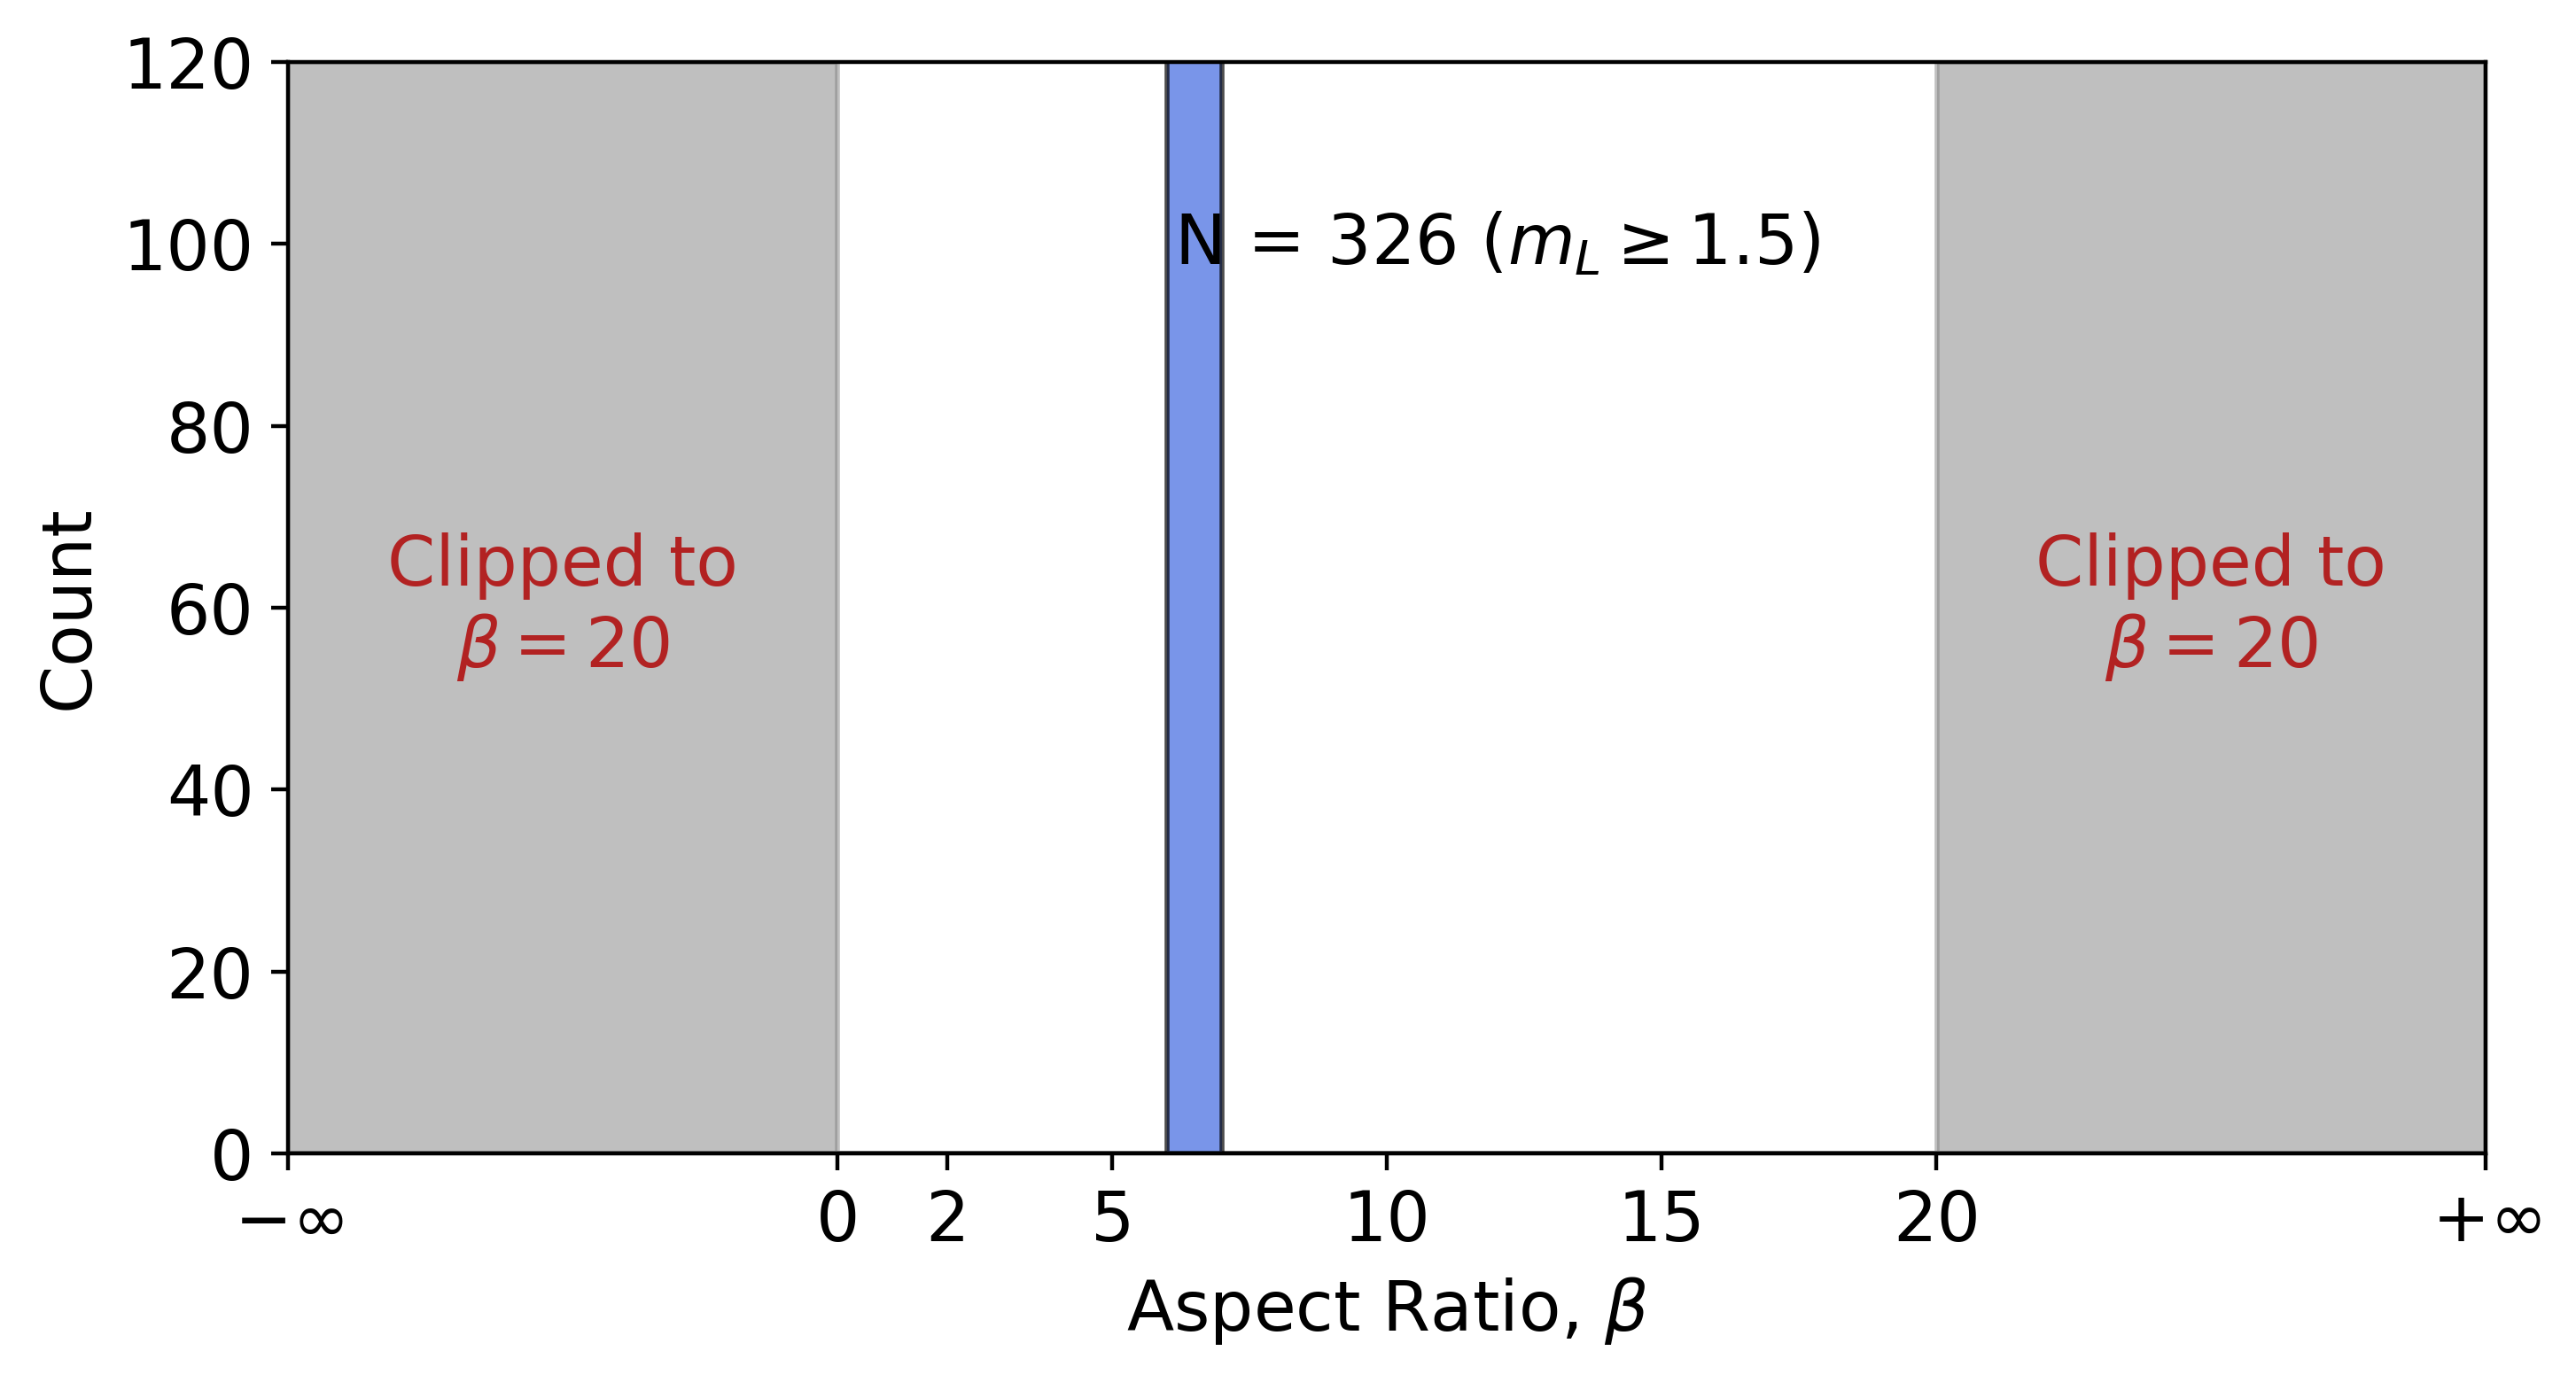

In [319]:
bins = np.r_[-1e4, 0, np.arange(1, 21, 1), 1e4]

fig, ax = plt.subplots(figsize = (8, 4), dpi = 400)

ax.hist(beta_all_original, bins=bins, color='royalblue', edgecolor='black', alpha = 0.7)

ax.set_xlim(-10, 30)
ax.set_ylim(0, 120)
ax.set_xlabel(r'Aspect Ratio, $\beta$')
ax.set_ylabel('Count')

ticks = [-10, 0, 2, 5, 10, 15, 20, 30]
labels = [r'$-\infty$', '0', '2', '5', '10', '15', '20', r'$+\infty$']

ax.set_xticks(ticks)
ax.set_xticklabels(labels)

ax.text(
    12, 100,
    r'N = 326 ($m_L$$\geq$1.5)',
    color='k',
    fontsize=14,
    ha='center',
    va='center'
)


ax.fill_betweenx(np.linspace(0, 120, 2), -10, 0 - 0.01, color='grey', alpha=0.5)
ax.text(
    -5, 60,
    'Clipped to\n' + r'$\beta=20$',
    color='firebrick',
    fontsize=14,
    ha='center',
    va='center' )

ax.fill_betweenx(np.linspace(0, 120, 2), 20 + 0.01, 30, color='grey', alpha=0.5)
ax.text(
    25, 60,
    'Clipped to\n' + r'$\beta=20$',
    color='firebrick',
    fontsize=14,
    ha='center',
    va='center' )

fig.savefig(f"{output_dir}/Fig_S8A.png", dpi=400, bbox_inches='tight')

In [320]:
# for i, beta in enumerate(beta_all):
#     if (beta < 2) & (beta > 0):
#         beta_all[i] = 2
#     elif (beta <= 0):
#         beta_all[i] = 20
#     elif beta > 20:
#         beta_all[i] = 20

In [321]:
def dynamic_upper_bound(beta, S1, Wi):
    S1 = np.asarray(S1, dtype=float)
    Wi = np.asarray(Wi, dtype=float)
    
    Mi = 0.59*beta*S1*Wi**3
    mi = 2/3*np.log10(Mi) - 6.07

    return mi 

In [322]:
# when 
Mw_bounds_all_allHi = np.full( H_hat_all_allHi.shape, np.empty )

for idx, S1 in  enumerate(S1_all):
    Whati = H_hat_all_allHi[idx, :]
    Wi = Whati * Hi / np.sin(dip_Huizinge)
    beta = beta_all[idx]
    Mw_bounds_all_allHi[idx, :] = dynamic_upper_bound(beta, S1, Wi)

In [323]:
Mw_bounds_all = np.full(len(date_all), np.nan)

for idx in range(len(date_all)):
    Mw_bounds_allHi = np.float64(Mw_bounds_all_allHi[idx,:])
    Mw_bounds_all[idx] = np.interp(  thickness_all[idx], Hi, Mw_bounds_allHi  )

In [324]:
np.interp(  310, Hi, np.float64(Mw_bounds_all_allHi[-1, :])  )

3.9002847205203426

## plot Mw bounds over P

In [325]:
pi = np.pi 
nu = 0.25


Hc_theory_all = (2*pi**3)/(pi**2 - 8*B_all**2)**2 * (Kc/S1_all)**2 * np.sin(dip_Huizinge)  - 4

M0_max_theory_all = pi/4*(1-nu)*S1_all*beta_all*( (1+16*B_all**2/pi**2)*Hc_theory_all/np.sin(dip_Huizinge) )**3

Mmax_theory_all = 2/3*np.log10(M0_max_theory_all) - 6.07  + 0.06

S1_theory_img = np.arange(1,20,0.1) * 1e6 

if version_scaling == 1:
    Hc_theory_img = (2*pi**3)/(pi**2 - 8*B_Huizinge**2)**2 * (Kc/S1_theory_img)**2 * np.sin(dip_Huizinge)  # - 4
    M0_max_theory_img = pi/4*(1-nu)*S1_theory_img*beta_Huizinge*( (1+16*B_Huizinge**2/pi**2)*Hc_theory_img/np.sin(dip_Huizinge) )**3
elif version_scaling == 2:
    B_theory_img = 1 - Sb_Huizinge / S1_theory_img
    Hc_theory_img = (2*pi**3)/(pi**2 - 8*B_theory_img**2)**2 * (Kc/S1_theory_img)**2 * np.sin(dip_Huizinge)  # - 4
    G0_theory_img = G0(S1_theory_img, Hc_theory_img / np.sin(dip_Huizinge), mu)
    beta_theory_img = beta_Huizinge * (Gc_Huizinge / G0_Huizinge - 1) / (Gc_Huizinge / G0_theory_img - 1)
    for i, beta in enumerate(beta_theory_img):
        if beta < 1:
            beta_theory_img[i] = 1
        elif beta > 20:
            beta_theory_img[i] = 20
    M0_max_theory_img = pi/4*(1-nu)*S1_theory_img*beta_theory_img*( (1+16*B_theory_img**2/pi**2)*Hc_theory_img/np.sin(dip_Huizinge) )**3

Mmax_theory_img = 2/3*np.log10(M0_max_theory_img) - 6.07  + 0.06
dpressure_mean_img = - Huizinge_DPRESSURE_mean * S1_theory_img / S1_Huizinge

In [326]:
targets = np.array([16, 18, 20, 22, 24, 26, 27], dtype=float)

nearest_idx = np.array([np.abs(dpressure_mean_all - t).argmin() for t in targets])
nearest_vals = dpressure_mean_all[nearest_idx]

print("targets:     ", targets)
print("indices:     ", nearest_idx)
print("values found:", nearest_vals)

targets:      [16. 18. 20. 22. 24. 26. 27.]
indices:      [  0  14  44  99 169 245 325]
values found: [16.00454374 18.05842508 19.97457415 21.99725723 24.01647105 26.01040156
 26.90700136]


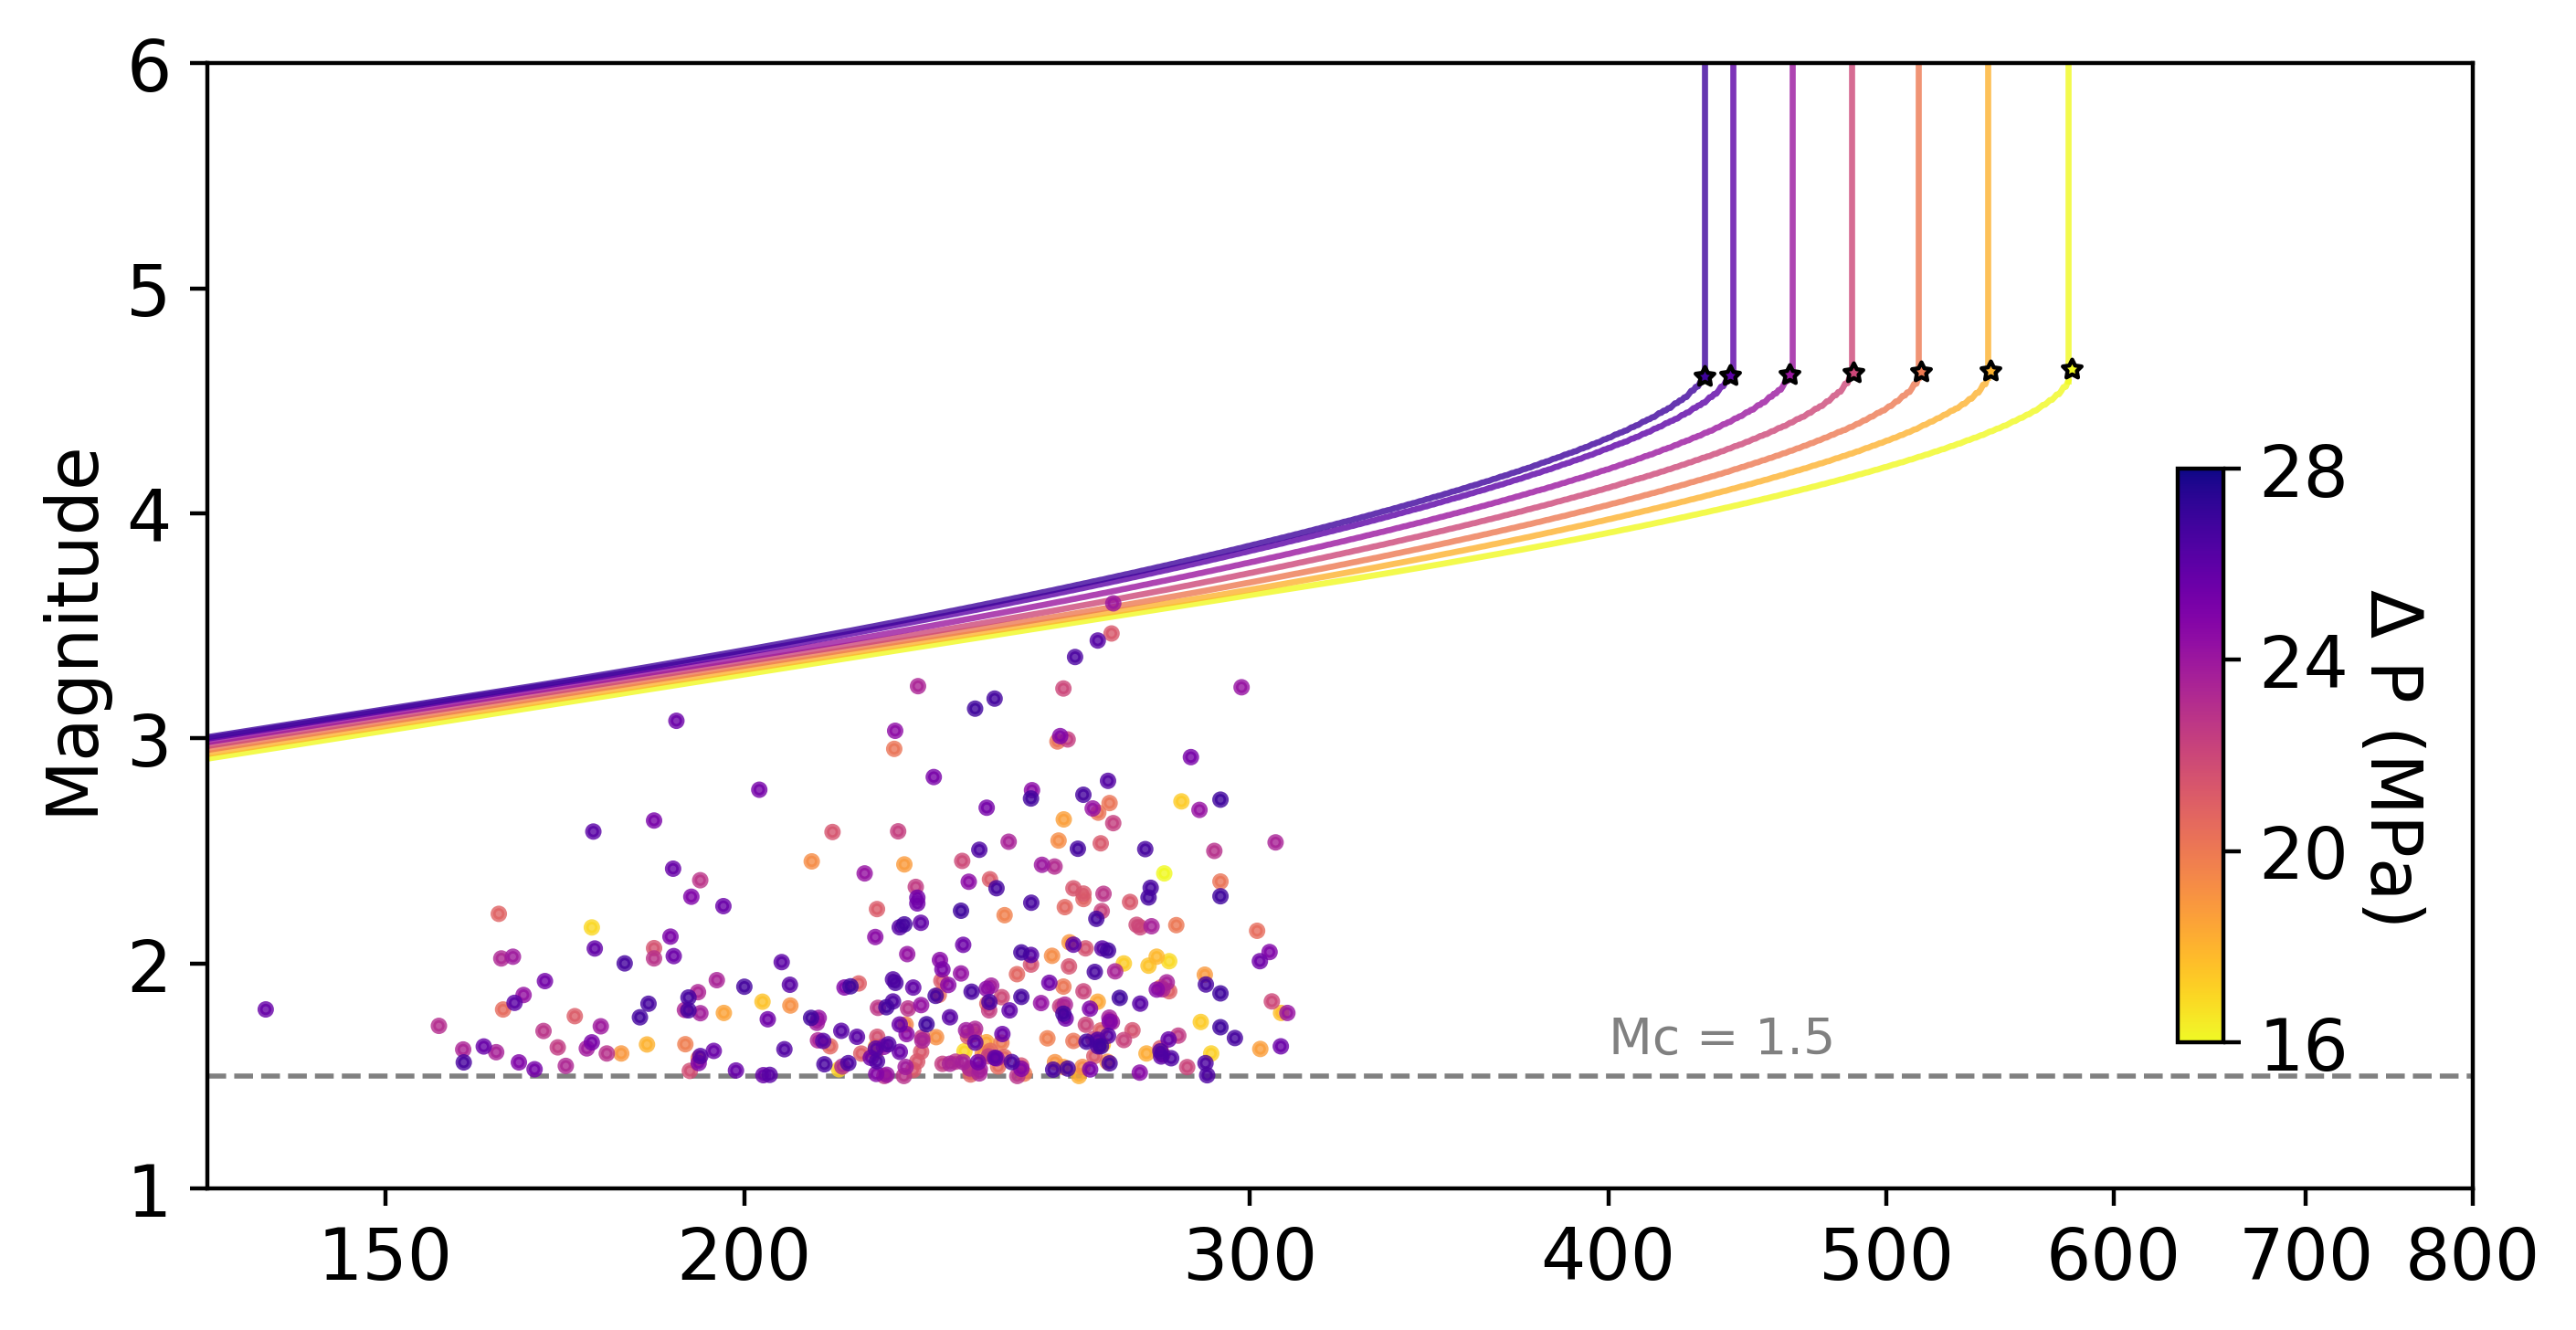

In [327]:
Mc = 1.5

def plot_thickness_magnitude_with_dp(fig, ax):

    # control these directly
    pad_x = 0.11   # horizontal distance from right edge of ax
    pad_y = 0.13   # vertical distance from bottom edge of ax
    cb_w  = 0.02  # colorbar width
    cb_h  = 0.51   # colorbar height

    cax = ax.inset_axes([
    1 - pad_x - cb_w,  # x0
    pad_y,             # y0
    cb_w,              # width
    cb_h               # height
    ])
    
    # cax = inset_axes(
    # ax,
    # width="3%",      # colorbar width relative to ax
    # height="55%",    # colorbar height relative to ax
    # loc="lower right",
    # borderpad = 4.0
    # )

    cmap = plt.get_cmap('plasma_r')

    # color bar 
    sm = plt.cm.ScalarMappable(cmap = cmap, norm=plt.Normalize(vmin = 16, vmax = 28))
    cbar = plt.colorbar(sm,cax = cax,  ax=ax, pad=0.01)
    cbar.set_label(r'$\Delta$ P (MPa)', rotation=270, labelpad=15)
    cbar.set_ticks([16, 20, 24, 28])
    
    for idx in nearest_idx: # range( 0, len(date_all), 60 ):
        # if if_arrest_list[idx_LEFM] == True:
        Mw_bound = np.asarray(Mw_bounds_all_allHi[idx,:], dtype=float)
        if ~np.all( np.isnan(Mw_bound) ):
            ax.plot(Hi, Mw_bound, color = sm.to_rgba(dpressure_mean_all[idx]), linewidth = 1.2, alpha = 0.8)
            if np.any( np.isnan(Mw_bound) ):  
                idx_lc = np.nanargmax(Mw_bound)
                Hc = Hi[idx_lc]
                Mcritical = Mw_bound[idx_lc]
                ax.plot( Hc*np.ones(20),  Mcritical + np.linspace(0, 6.0 - Mcritical, 20), color = sm.to_rgba(dpressure_mean_all[idx]), linewidth = 1.2, alpha = 0.8  )
            
                # print(Hc, Hc_theory_all[idx], Mcritical, Mmax_theory_all[idx])

                ax.scatter(Hc_theory_all[idx], Mmax_theory_all[idx], 
                           marker = (5,1), color = sm.to_rgba(dpressure_mean_all[idx]), s = 15, 
                           edgecolor='k', linewidth = 0.8,   zorder=10  )
    
    # Theoretical Mmax_arrested line
    # ax.scatter(Hc_theory_all, Mmax_theory, color = sm.to_rgba(dpressure_mean_all), s = 1 )#, edgecolor='k', s = 10, zorder=5, label='Theoretical Upper Bound'  )
    # ax.plot(Hc_theory_img, Mmax_theory_img, 'k--', linewidth = 0.8, alpha = 0.8 )

    # KNMI catalog
    sc = ax.scatter(thickness_all, magnitude_all, c = sm.to_rgba(dpressure_mean_all), facecolor = 'k', s=5, alpha = 0.8, zorder = 5)

    # ax.legend(
    #     loc='lower right',
    #     fontsize = 10,
    #     bbox_to_anchor=(800, 1.5),   # data coordinates
    #     bbox_transform=ax.transData
    # )

    # Mc
    ax.axhline(y=Mc, color='gray', linestyle='--', linewidth=1)
    ax.text(400, Mc + 0.1, f'Mc = {Mc}', color='gray', fontsize=10)

    
    # scaling line
    color_scale =   "#264653" # "#2F3E46"  # "#334155" # "#264653"  # teal, C0
    xmin, xmax, ymax = 150, 250, 4.17
    """
    # M0 ~ H^3 
    slope = 3
    ymin = ymax - 2/3*slope * np.log10(xmax/xmin)

    ax.plot([xmin, xmax],[ymin,ymax],'-', c = color_scale, linewidth = 1, alpha = 0.8 )   
    ax.text(xmin, ymin - 0.2, r'$M_0$ ~ $H^3$', color=color_scale, fontsize=10, alpha = 0.8)
    """
    # M0 ~ H^5/2 scaling line
    if version_scaling == 1:
        slope = 5/2
        ymin = ymax - 2/3*slope * np.log10(xmax/xmin)
        # ax.plot([xmin, xmax],[ymin,ymax],'-', c = color_scale, linewidth = 1, alpha = 0.8 )   
        ax.text(xmin, ymin + 0.2, r'$M_0$ = $\gamma  H^{5/2}$', color = 'k', fontsize=10, alpha = 0.8)
    

    # ax.set_title('Arbitrary Model Parameters')
    ax.set_xscale('log' )
    # ax.set_xlabel('Reservoir Thickness (m)')
    ax.set_ylabel('Magnitude')

    ax.set_xlim(130, 800)
    ax.set_ylim(1.0, 6.0)
    ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter('{x:.0f}'))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xticks([150, 200,  300, 400, 500, 600, 700, 800])
    # ax.xaxis.set_minor_locator(mpl.ticker.LogLocator(base=10.0, subs=np.arange(1.0, 100.0) * 0.01, numticks=10))
    return fig, ax

fig, ax = plt.subplots(figsize=(8, 4), dpi = 400)
fig, ax = plot_thickness_magnitude_with_dp(fig, ax)

fig.savefig(f"{output_dir}/Fig_3A.png", bbox_inches='tight', dpi = 400)

In [328]:
stop

NameError: name 'stop' is not defined

## synthetic catalog

In [329]:
def b_TGR_for_allEQ( x ):
    b_min = 0.7 # 0.7
    b_max = 1.1 # 1.1
    xmin = 220 # 220
    xmax = 260 # 260
    x_arr = np.asarray(x, dtype=float)
    y = b_max + (b_min - b_max) * (x_arr - xmin) / (xmax - xmin)
    y = np.clip(y, b_min, b_max)
    return y.item() if np.isscalar(x) else y

In [330]:
seeds = range(20000)
b_TGR_all = b_TGR_for_allEQ( thickness_all )

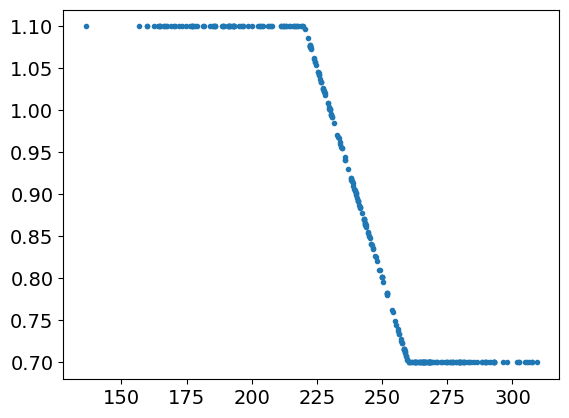

In [331]:
plt.plot(thickness_all, b_TGR_all, '.')

In [332]:
def Random_Mw_generator(Mmax, Mm, b, U):
    return Mmax - (1/b)*np.log10(  U + (1-U)*10**(b*(Mmax - Mm))   )

def generate_synthetic_catalog(seeds, b_TGR, Mw_theory):
    assert len(b_TGR) == len(Mw_theory), "Length of bins, counts, and b-values must match" # len(date_all)
    
    
    Mw_synthetic_allseeds = np.full( [len(seeds), len(b_TGR) ], fill_value=np.empty )

    for idx_seed, seed in  enumerate(seeds):
        m_syn_seed = np.full(len(b_TGR), fill_value=np.empty)
        
        rng_mag = np.random.default_rng(seed = seed)
        U_samples_mag = rng_mag.uniform(0, 1, len(b_TGR))
        
        
        m_syn_seed = Random_Mw_generator( Mmax = Mw_theory, Mm = 1.5, b = b_TGR, U = U_samples_mag ) 
        
        Mw_synthetic_allseeds[idx_seed, :] = np.array( m_syn_seed )


    return Mw_synthetic_allseeds
    

In [333]:
m_synthetic_allseeds_all = np.full( [len(seeds),len(date_all)], fill_value = np.empty )

m_synthetic_allseeds_all = generate_synthetic_catalog(seeds, b_TGR_all, Mw_bounds_all)    

## $m_{max}$

In [334]:
# my hand-written version

"""
m_max_lower_alltime = np.full( len(date_all), fill_value=np.nan )
m_max_median_alltime = np.full( len(date_all), fill_value=np.nan )
m_max_upper_alltime = np.full( len(date_all), fill_value=np.nan )

for idx in range(len(date_all)):
    m_max_allseeds = np.max(m_synthetic_allseeds_all[:, :idx+1], axis = 1) # (10000,)
    q05, q50, q95 = np.quantile(m_max_allseeds, [0.05, 0.50, 0.95])
    m_max_lower_alltime[idx] = q05
    m_max_median_alltime[idx] = q50
    m_max_upper_alltime[idx] = q95
"""

'\nm_max_lower_alltime = np.full( len(date_all), fill_value=np.nan )\nm_max_median_alltime = np.full( len(date_all), fill_value=np.nan )\nm_max_upper_alltime = np.full( len(date_all), fill_value=np.nan )\n\nfor idx in range(len(date_all)):\n    m_max_allseeds = np.max(m_synthetic_allseeds_all[:, :idx+1], axis = 1) # (10000,)\n    q05, q50, q95 = np.quantile(m_max_allseeds, [0.05, 0.50, 0.95])\n    m_max_lower_alltime[idx] = q05\n    m_max_median_alltime[idx] = q50\n    m_max_upper_alltime[idx] = q95\n'

In [335]:
m_syn = np.asarray(m_synthetic_allseeds_all, dtype=float)  # shape: (n_seeds, n_events)

# Cumulative maximum per seed across time/events
cummax_syn = np.maximum.accumulate(m_syn, axis=1)  # shape: (n_seeds, n_events)

# Quantiles across seeds at each time index
m_max_lower_alltime, m_max_median_alltime, m_max_upper_alltime = np.quantile(
    cummax_syn, [0.05, 0.50, 0.95], axis=0 )

# Keep compatibility with variables used later / for inspection
idx = len(date_all) - 1
m_max_allseeds = cummax_syn[:, idx]
q05, q50, q95 = (
    m_max_lower_alltime[idx],
    m_max_median_alltime[idx],
    m_max_upper_alltime[idx],
)

In [336]:
b_GR = 1

def Mmax_GR_mode_theory(mc, b, N):
    return mc + (1/b)*np.log10( N )
def Mmax_GR_prob_theory(mc, b, N, q):
    return mc - (1/b)*np.log10( 1 - q**(1/N) )

m_max_GR_lower_alltime = np.full( len(date_all), fill_value=np.nan )
m_max_GR_mode_alltime = np.full( len(date_all), fill_value=np.nan )
m_max_GR_upper_alltime = np.full( len(date_all), fill_value=np.nan )
m_max_GR_median_alltime = np.full( len(date_all), fill_value=np.nan )

for idx in range(len(date_all)):
    N = idx + 1
    m_max_GR_lower_alltime[idx] = Mmax_GR_prob_theory(Mc, b_GR, N, 0.05)
    m_max_GR_mode_alltime[idx] = Mmax_GR_mode_theory(Mc, b_GR, N)
    m_max_GR_median_alltime[idx] = Mmax_GR_prob_theory(Mc, b_GR, N, 0.50)
    m_max_GR_upper_alltime[idx] = Mmax_GR_prob_theory(Mc, b_GR, N, 0.95)

In [337]:
# cumulative maximum of magnitude_all up to each date_all
mag_max_upto_each = np.maximum.accumulate(magnitude_all)

In [338]:
# date_windows = [ date_all[end] for start, end in bin_ranges ]
# Nevents_windows = [ end - start for start, end in bin_ranges ]
# dpressure_mean_windows = [ - np.interp(date_all[end], DPRESSURE_time, DPRESSURE_mean) for start, end in bin_ranges ]

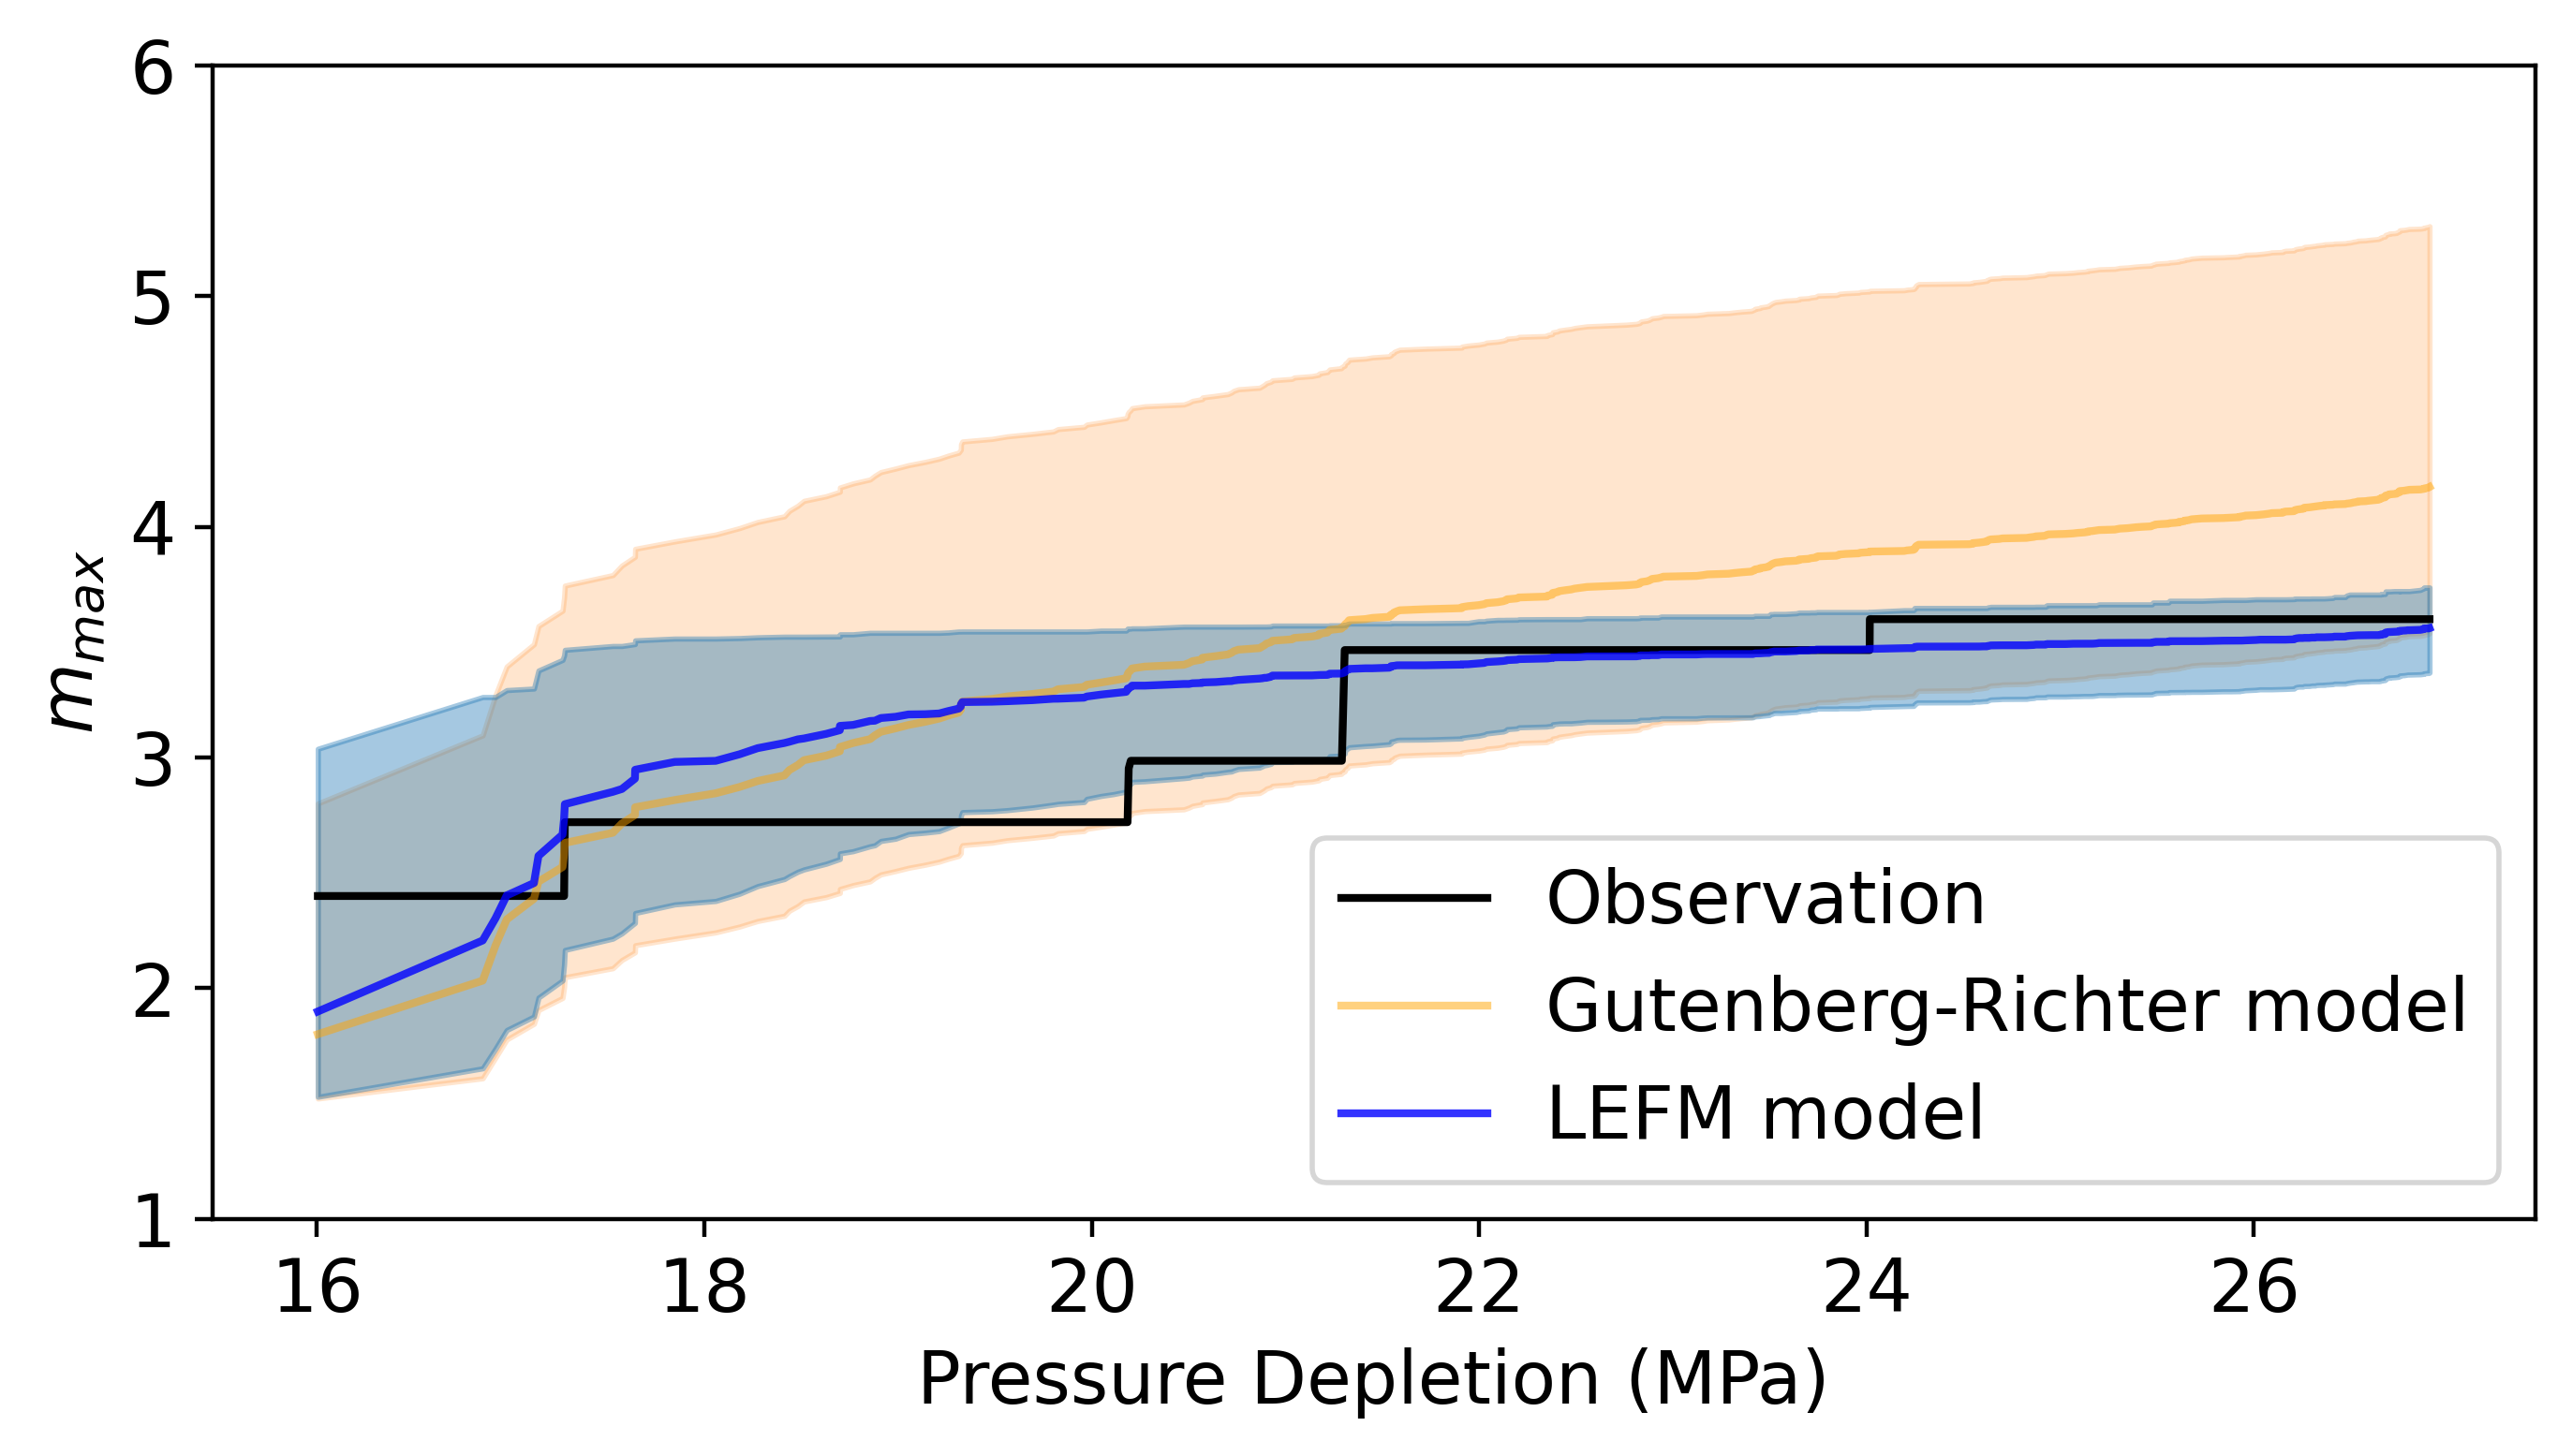

In [339]:
fig, ax = plt.subplots( figsize=(8, 4), dpi = 400 )
# data
l_data = ax.plot(dpressure_mean_all, mag_max_upto_each, 'k', label = 'Observation')

# GR
# ax.plot(dpressure_mean_windows, m_max_GR_mode_alltime, color = 'orange', alpha = 0.5)
l_GR = ax.plot(dpressure_mean_all, m_max_GR_median_alltime, color = 'orange', alpha = 0.5, label = 'Gutenberg-Richter model')
ax.fill_between(dpressure_mean_all, m_max_GR_lower_alltime, m_max_GR_upper_alltime, color='C1', alpha=0.2 )

# model
l_model = ax.plot(dpressure_mean_all, m_max_median_alltime, 'b-', alpha = 0.8, label = 'LEFM model')
ax.fill_between(dpressure_mean_all, m_max_lower_alltime, m_max_upper_alltime, color='C0', alpha=0.4 )

# Max arrested
# ax.plot(dpressure_mean_img, Mmax_theory_img, 'k--', linewidth = 0.8, alpha = 0.8 )

# ax.set_xlim(1990, 2025)
ax.set_xlabel('Pressure Depletion (MPa)')
ax.set_ylabel(r'$m_{max}$')

ax.set_ylim(1, 6)

ax.legend(
    loc='lower right',
    fontsize = 14,
    bbox_to_anchor=(1.0, 0.0),   # data coordinates
    bbox_transform=ax.transAxes
)

fig.savefig(f'{output_dir}/Fig_4D.png', bbox_inches='tight', dpi = 400)

In [340]:
stop

NameError: name 'stop' is not defined

## MFD

In [341]:
centers_m = np.arange(15, 40) / 10

In [342]:
def MFD(Mag, centers):
    counts = np.array([(Mag >= center).sum() for center in centers])
    return counts

def MFD_v2(Mw_synthetic_eachtime_allseeds):
    # Mw_synthetic_eachtime_allseeds shape: (n_seeds, n_events)
    n_events = Mw_synthetic_eachtime_allseeds.shape[1]
    centers_N = np.arange(1, n_events + 1, 1) 
    idx_take = n_events - centers_N  # equivalent to negative indexing -centers_N

    Mw_sorted = np.sort(Mw_synthetic_eachtime_allseeds, axis=1)
    Mw_ranked = Mw_sorted[:, idx_take]  # shape: (n_seeds, len(centers_N))

    q05, q50, q95 = np.quantile(Mw_ranked, [0.05, 0.50, 0.95], axis=0)
    q50 = np.asarray(q50, dtype=float)
    q05 = np.asarray(q05, dtype=float)
    q95 = np.asarray(q95, dtype=float)
    return q50, q05, q95

In [343]:
def plot_MFD_synthetic(fig, ax, centers_m, magnitude, centers_N, MFD_synthetic_v2_median, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper, time_start, time_end):
    # N = 326
    ax.plot(MFD_synthetic_v2_median, centers_N, 'b-', alpha = 1 )
    # ax.plot(centers, MFD_synthetic_mean, 'b-', alpha = 1 )
    
    ax.fill_betweenx(centers_N, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper, alpha=0.4, color='C0')
    
    # KNMI catalog
    ax.plot(centers_m, MFD(magnitude, centers_m), 'k.', label=f'KNMI ({time_start:.1f}-{time_end:.1f})')

    ax.set_xlabel('Magnitude')
    ax.set_ylabel(r'N ($\geq$M)')
    # ax.set_title(r"truncated GR, thickness-dependent b $\in$ [0.7, 1.3]", fontsize = 14)

    ax.set_yscale('log')
    ax.set_xlim(1.5, 6.0)
    ax.set_ylim(1, 1000)
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)

    ax.legend(
        loc='upper right',
        fontsize = 12
    )

    plt.tight_layout()

    return fig, ax


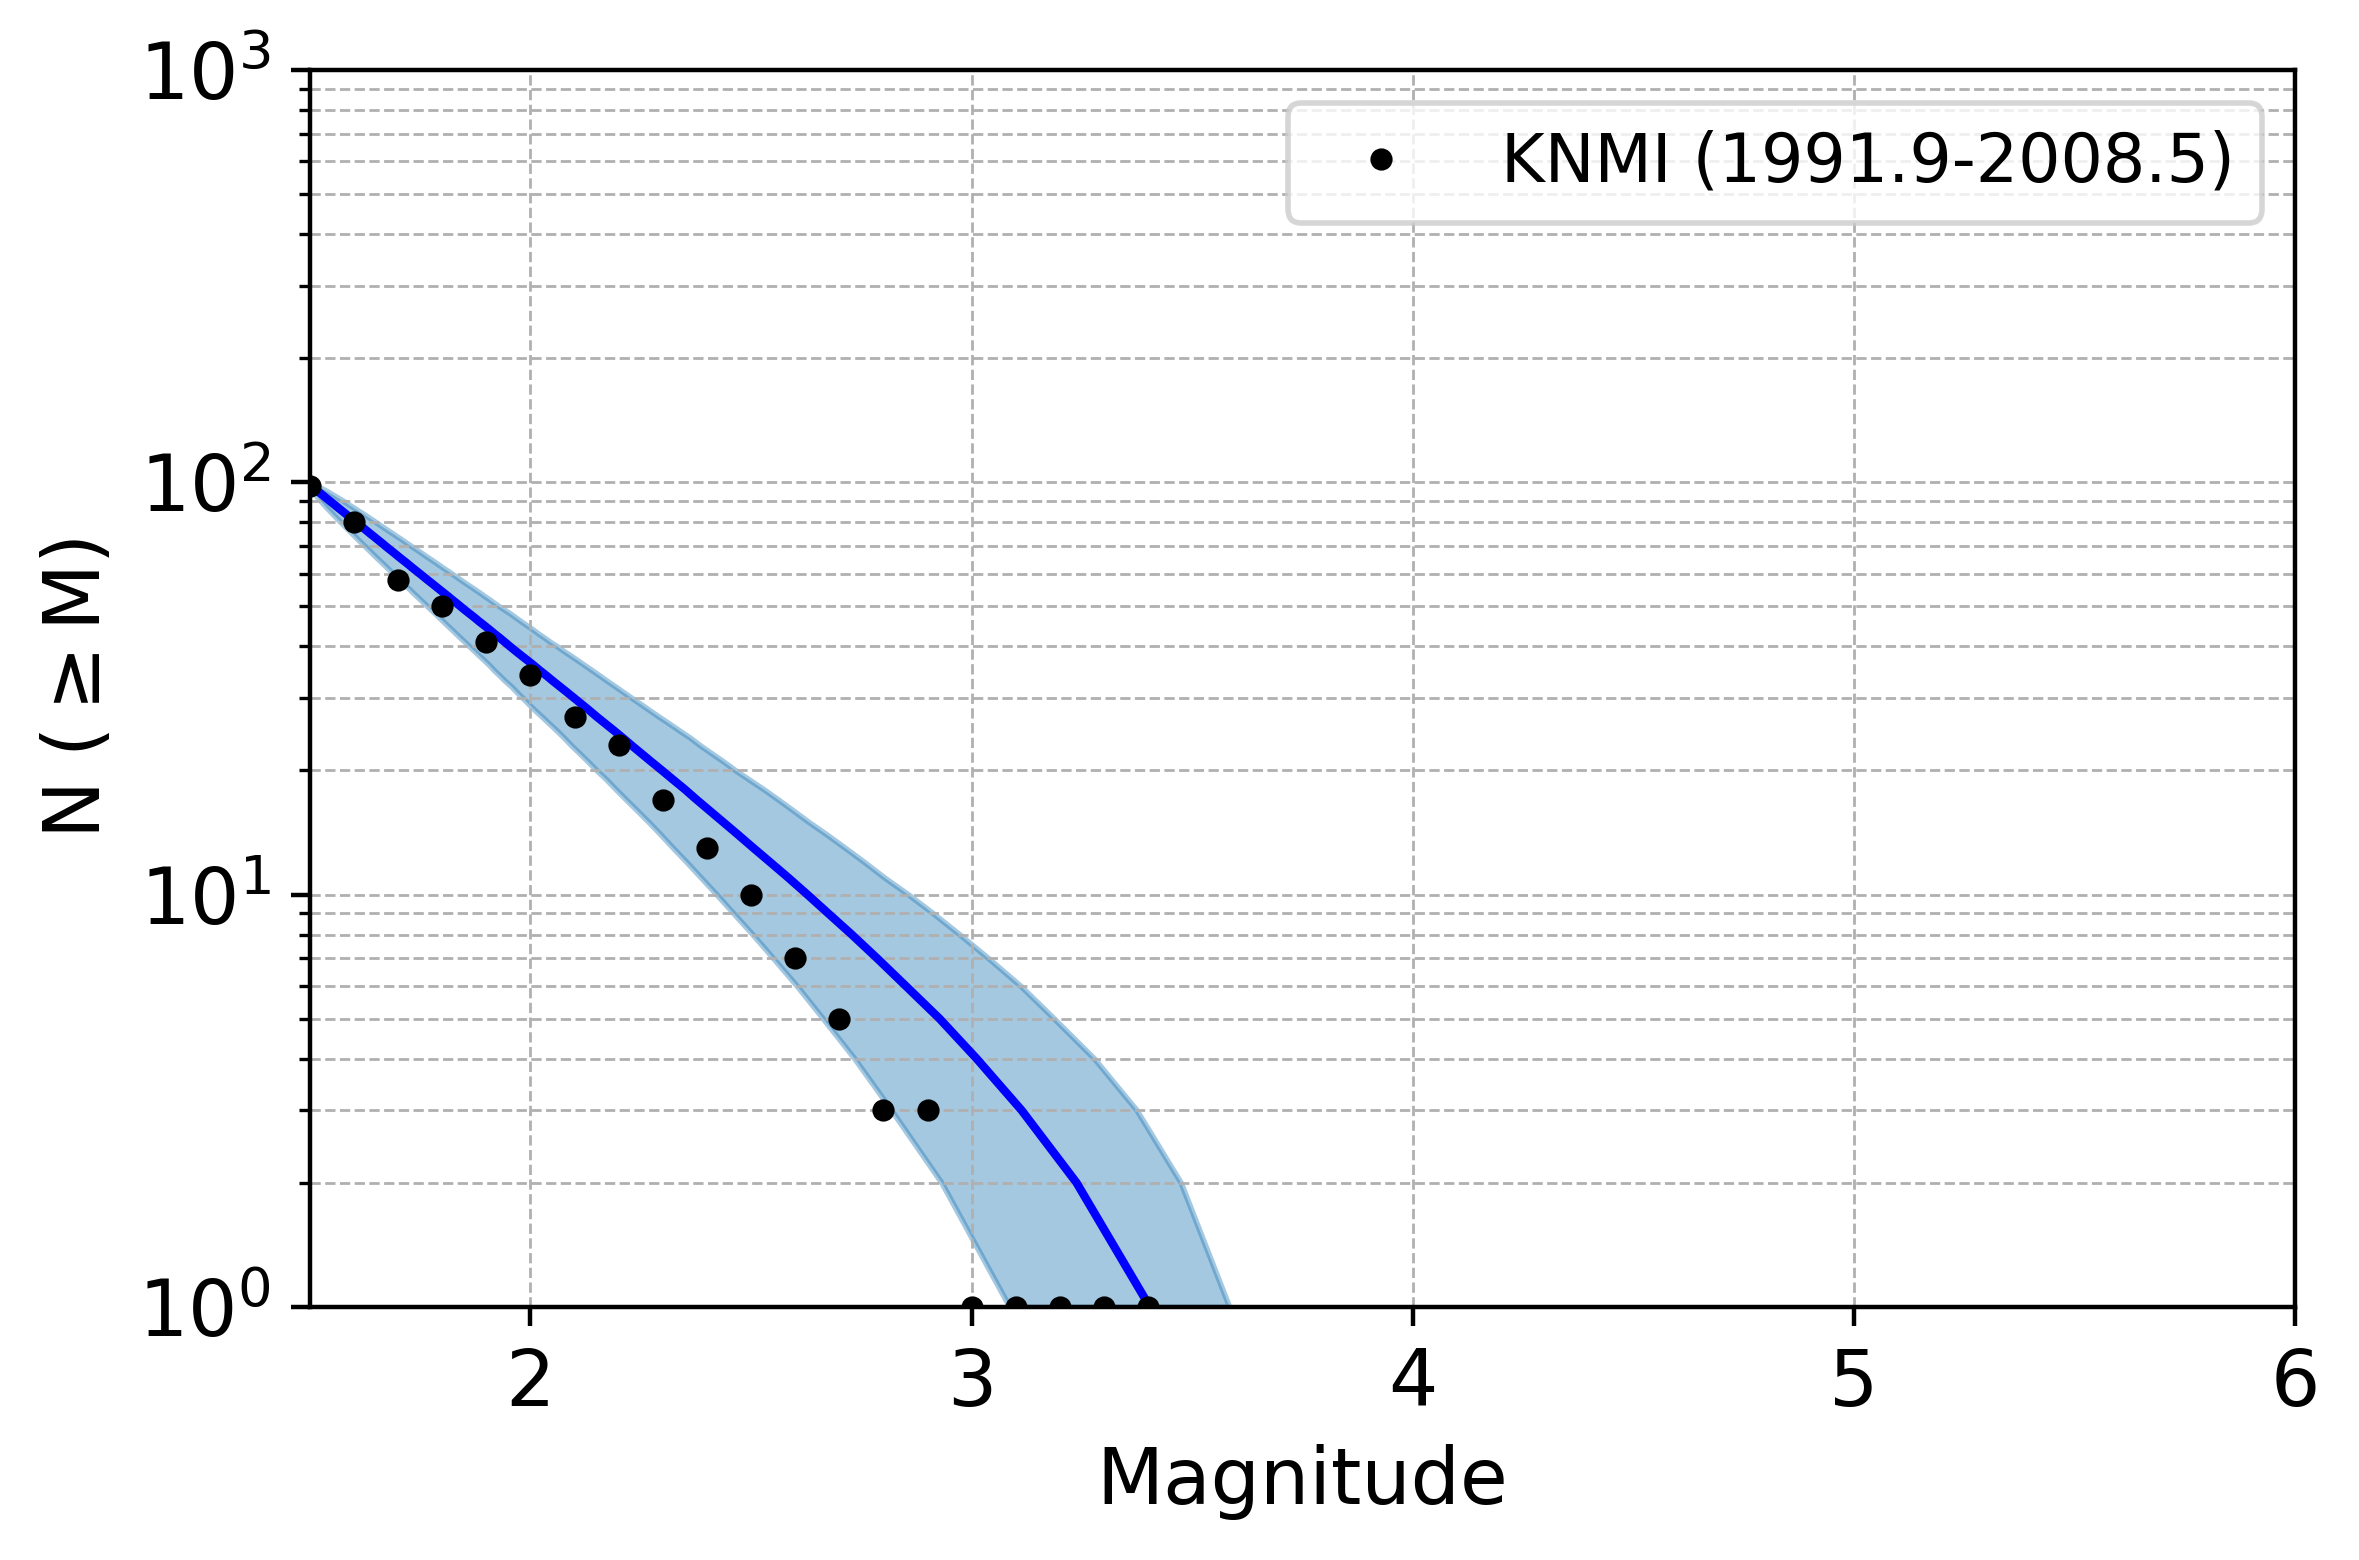

In [344]:
idx = 98 # the first {idx + 1} events
m_data = magnitude_all[:idx]
m_synthetic_allseeds = m_synthetic_allseeds_all[:, :idx]

centers_N = np.arange(1, idx + 1, 1)
MFD_synthetic_v2_median, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper = MFD_v2( m_synthetic_allseeds )

fig, ax = plt.subplots(figsize=(6, 4), dpi = 400)
fig, ax = plot_MFD_synthetic(fig, ax, centers_m, m_data, centers_N, MFD_synthetic_v2_median, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper, 
                                date_all[0], date_all[idx] )

plt.show(fig)


In [345]:
# N = 1000 (triple number, while keeping the spatial-temporal frequency the same)
Mw_bounds_all_N1000 = np.repeat(Mw_bounds_all, 3)
b_TGR_all_N1000 = np.repeat(b_TGR_all, 3)

m_synthetic_N1000 = generate_synthetic_catalog(seeds, b_TGR_all_N1000, Mw_bounds_all_N1000)  

centers_N_N1000 = np.arange(1, 326 * 3 + 1, 1)

MFD_synthetic_v2_median_N1000, MFD_synthetic_v2_lower_N1000, MFD_synthetic_v2_upper_N1000 = MFD_v2( m_synthetic_N1000 )


In [346]:
# N = 326
centers_N = np.arange(1, 327, 1)
MFD_synthetic_v2_median, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper = MFD_v2( m_synthetic_allseeds_all )


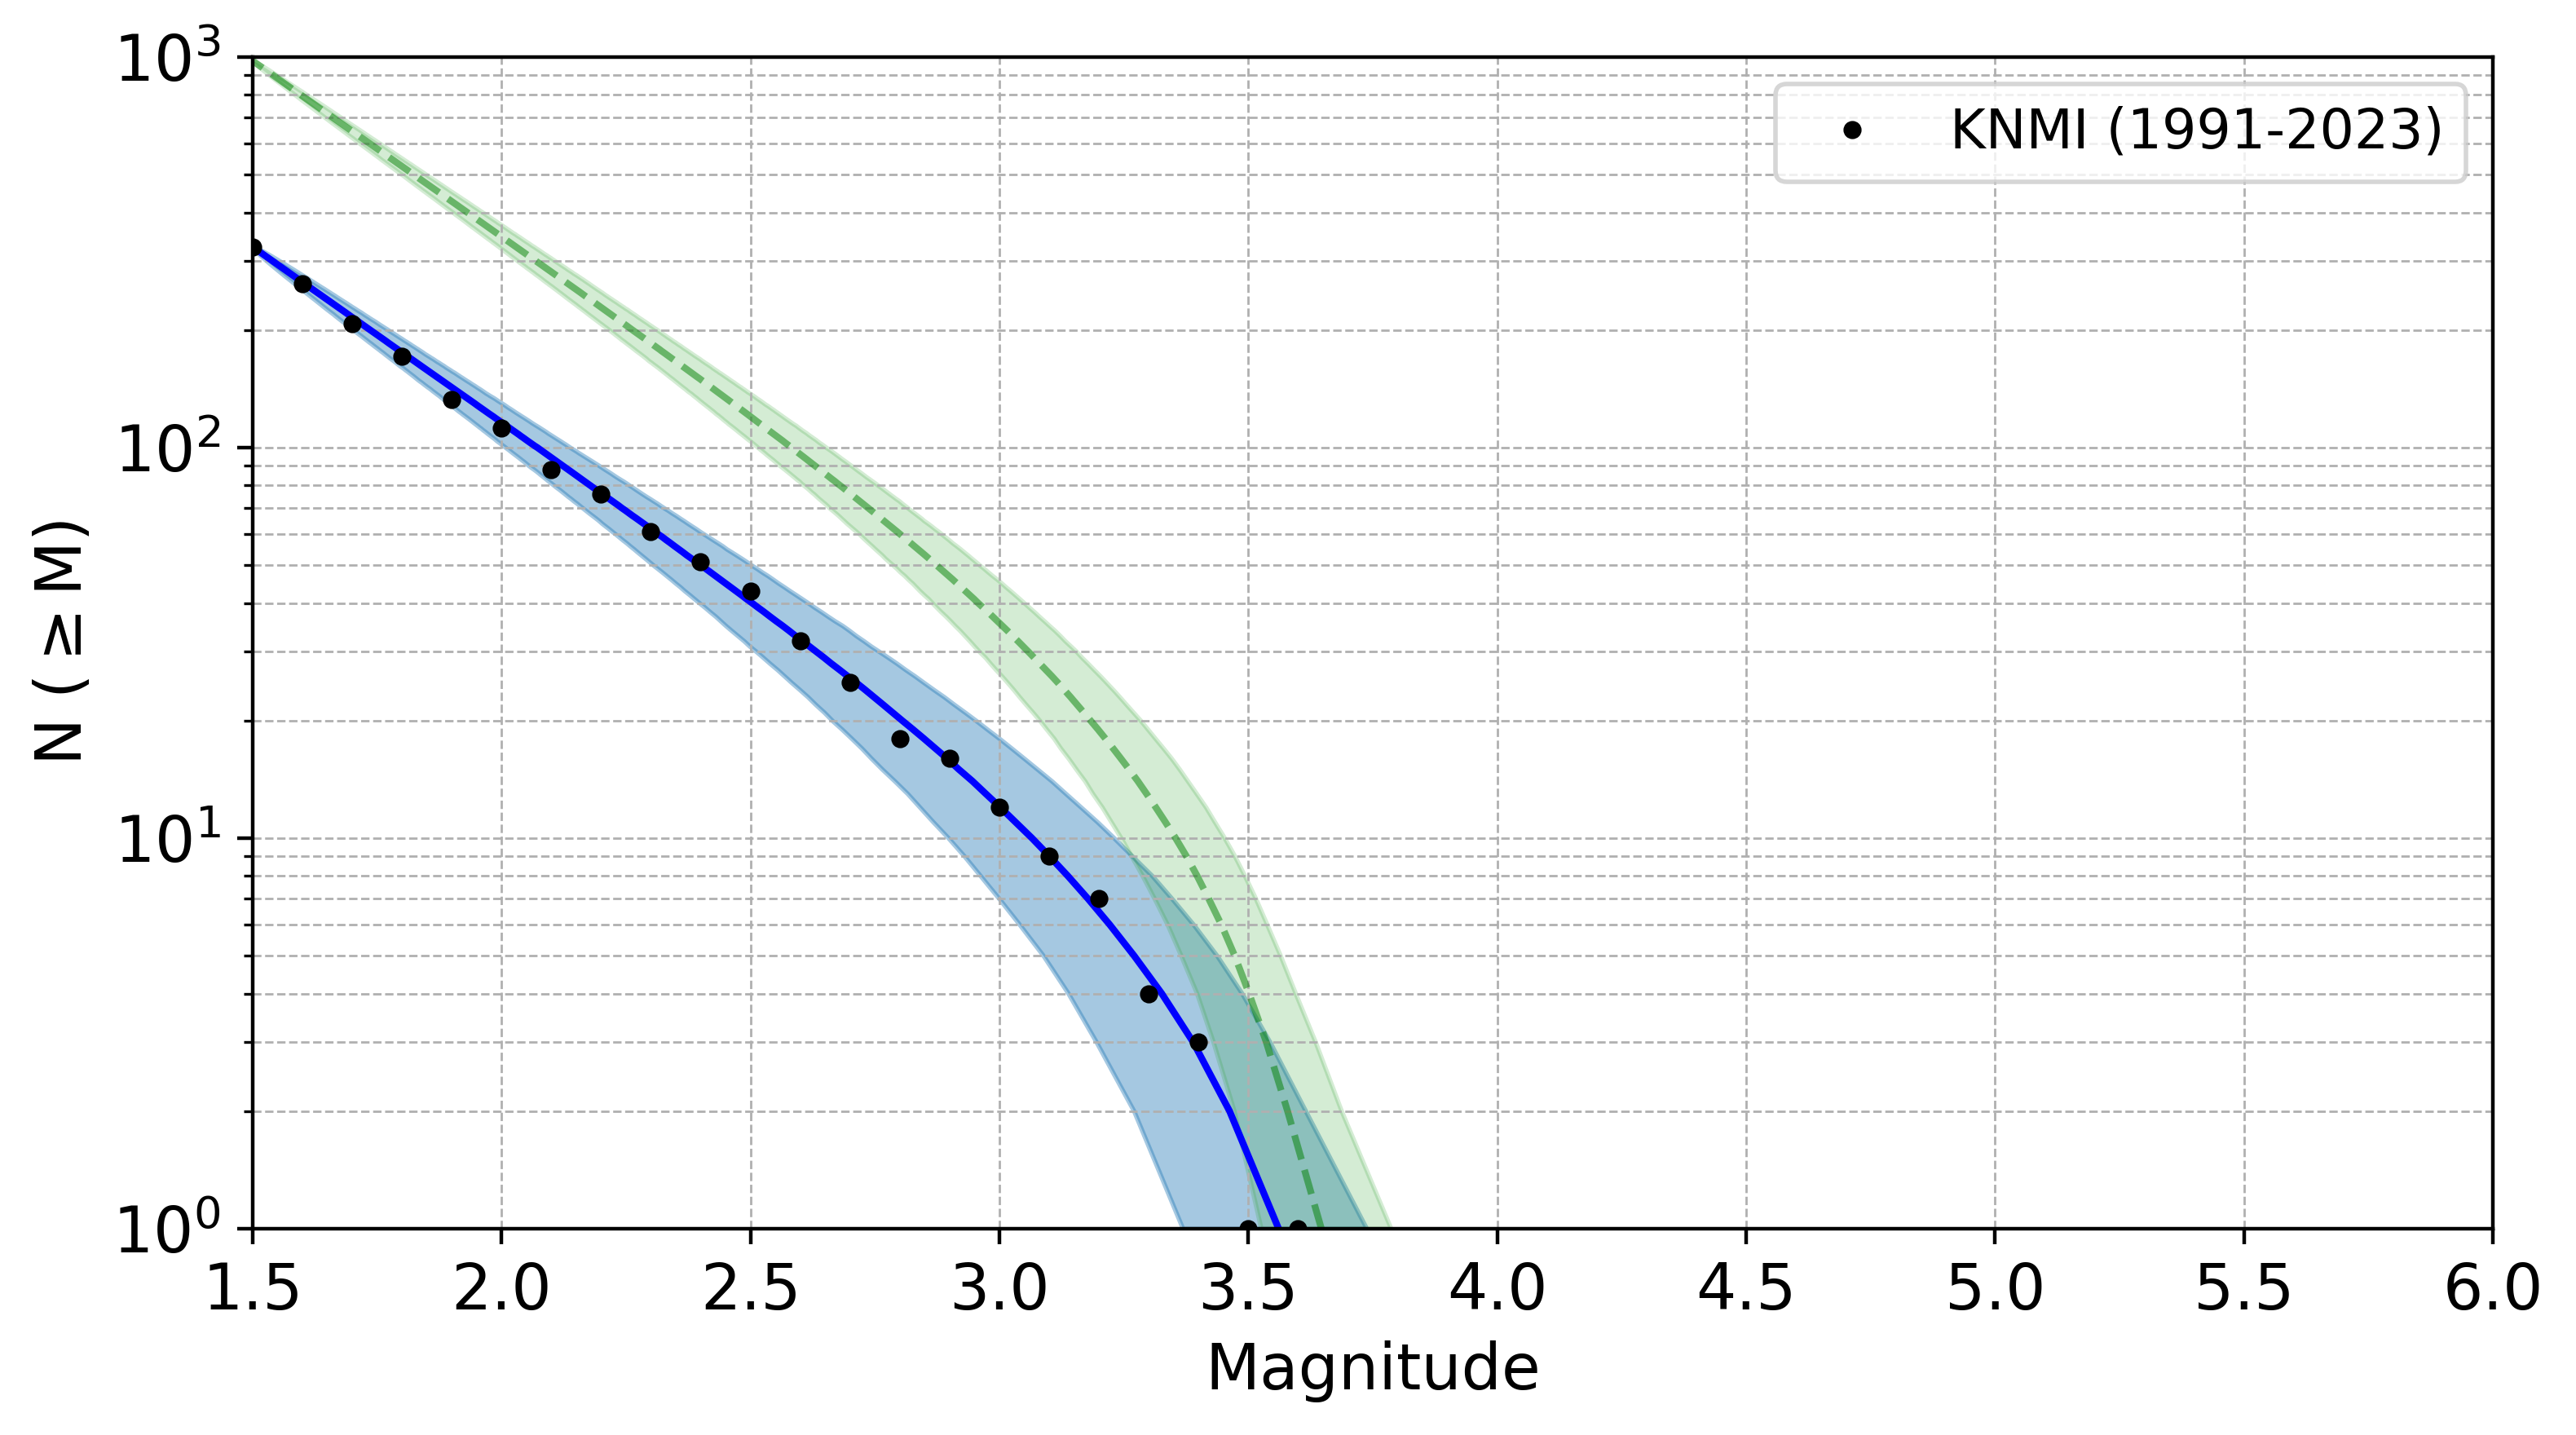

In [347]:

fig, ax = plt.subplots(figsize=(8, 4.5), dpi = 400)

ax.plot(MFD_synthetic_v2_median, centers_N, 'b-', alpha = 1 )

ax.fill_betweenx(centers_N, MFD_synthetic_v2_lower, MFD_synthetic_v2_upper, alpha=0.4, color='C0')

# KNMI catalog
ax.plot(centers_m, MFD(magnitude_all, centers_m), 'k.', label=f'KNMI (1991-2023)')

ax.set_xlabel('Magnitude')
ax.set_ylabel(r'N ($\geq$M)')
# ax.set_title(r"truncated GR, thickness-dependent b $\in$ [0.7, 1.3]", fontsize = 14)

ax.set_yscale('log')
ax.set_xlim(1.5, 6.0)
ax.set_ylim(1, 1000)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.legend(
    loc='upper right',
    fontsize = 12)

ax.plot(MFD_synthetic_v2_median_N1000, centers_N_N1000, 'g--', alpha = 0.5 )

ax.fill_betweenx(centers_N_N1000, MFD_synthetic_v2_lower_N1000, MFD_synthetic_v2_upper_N1000, alpha=0.2, color='C2')


plt.tight_layout()

fig.savefig(f'{output_dir}/Fig_4A.png', bbox_inches='tight', dpi=400)

  0%|          | 0/23 [00:00<?, ?it/s]

100%|██████████| 23/23 [00:05<00:00,  4.42it/s]


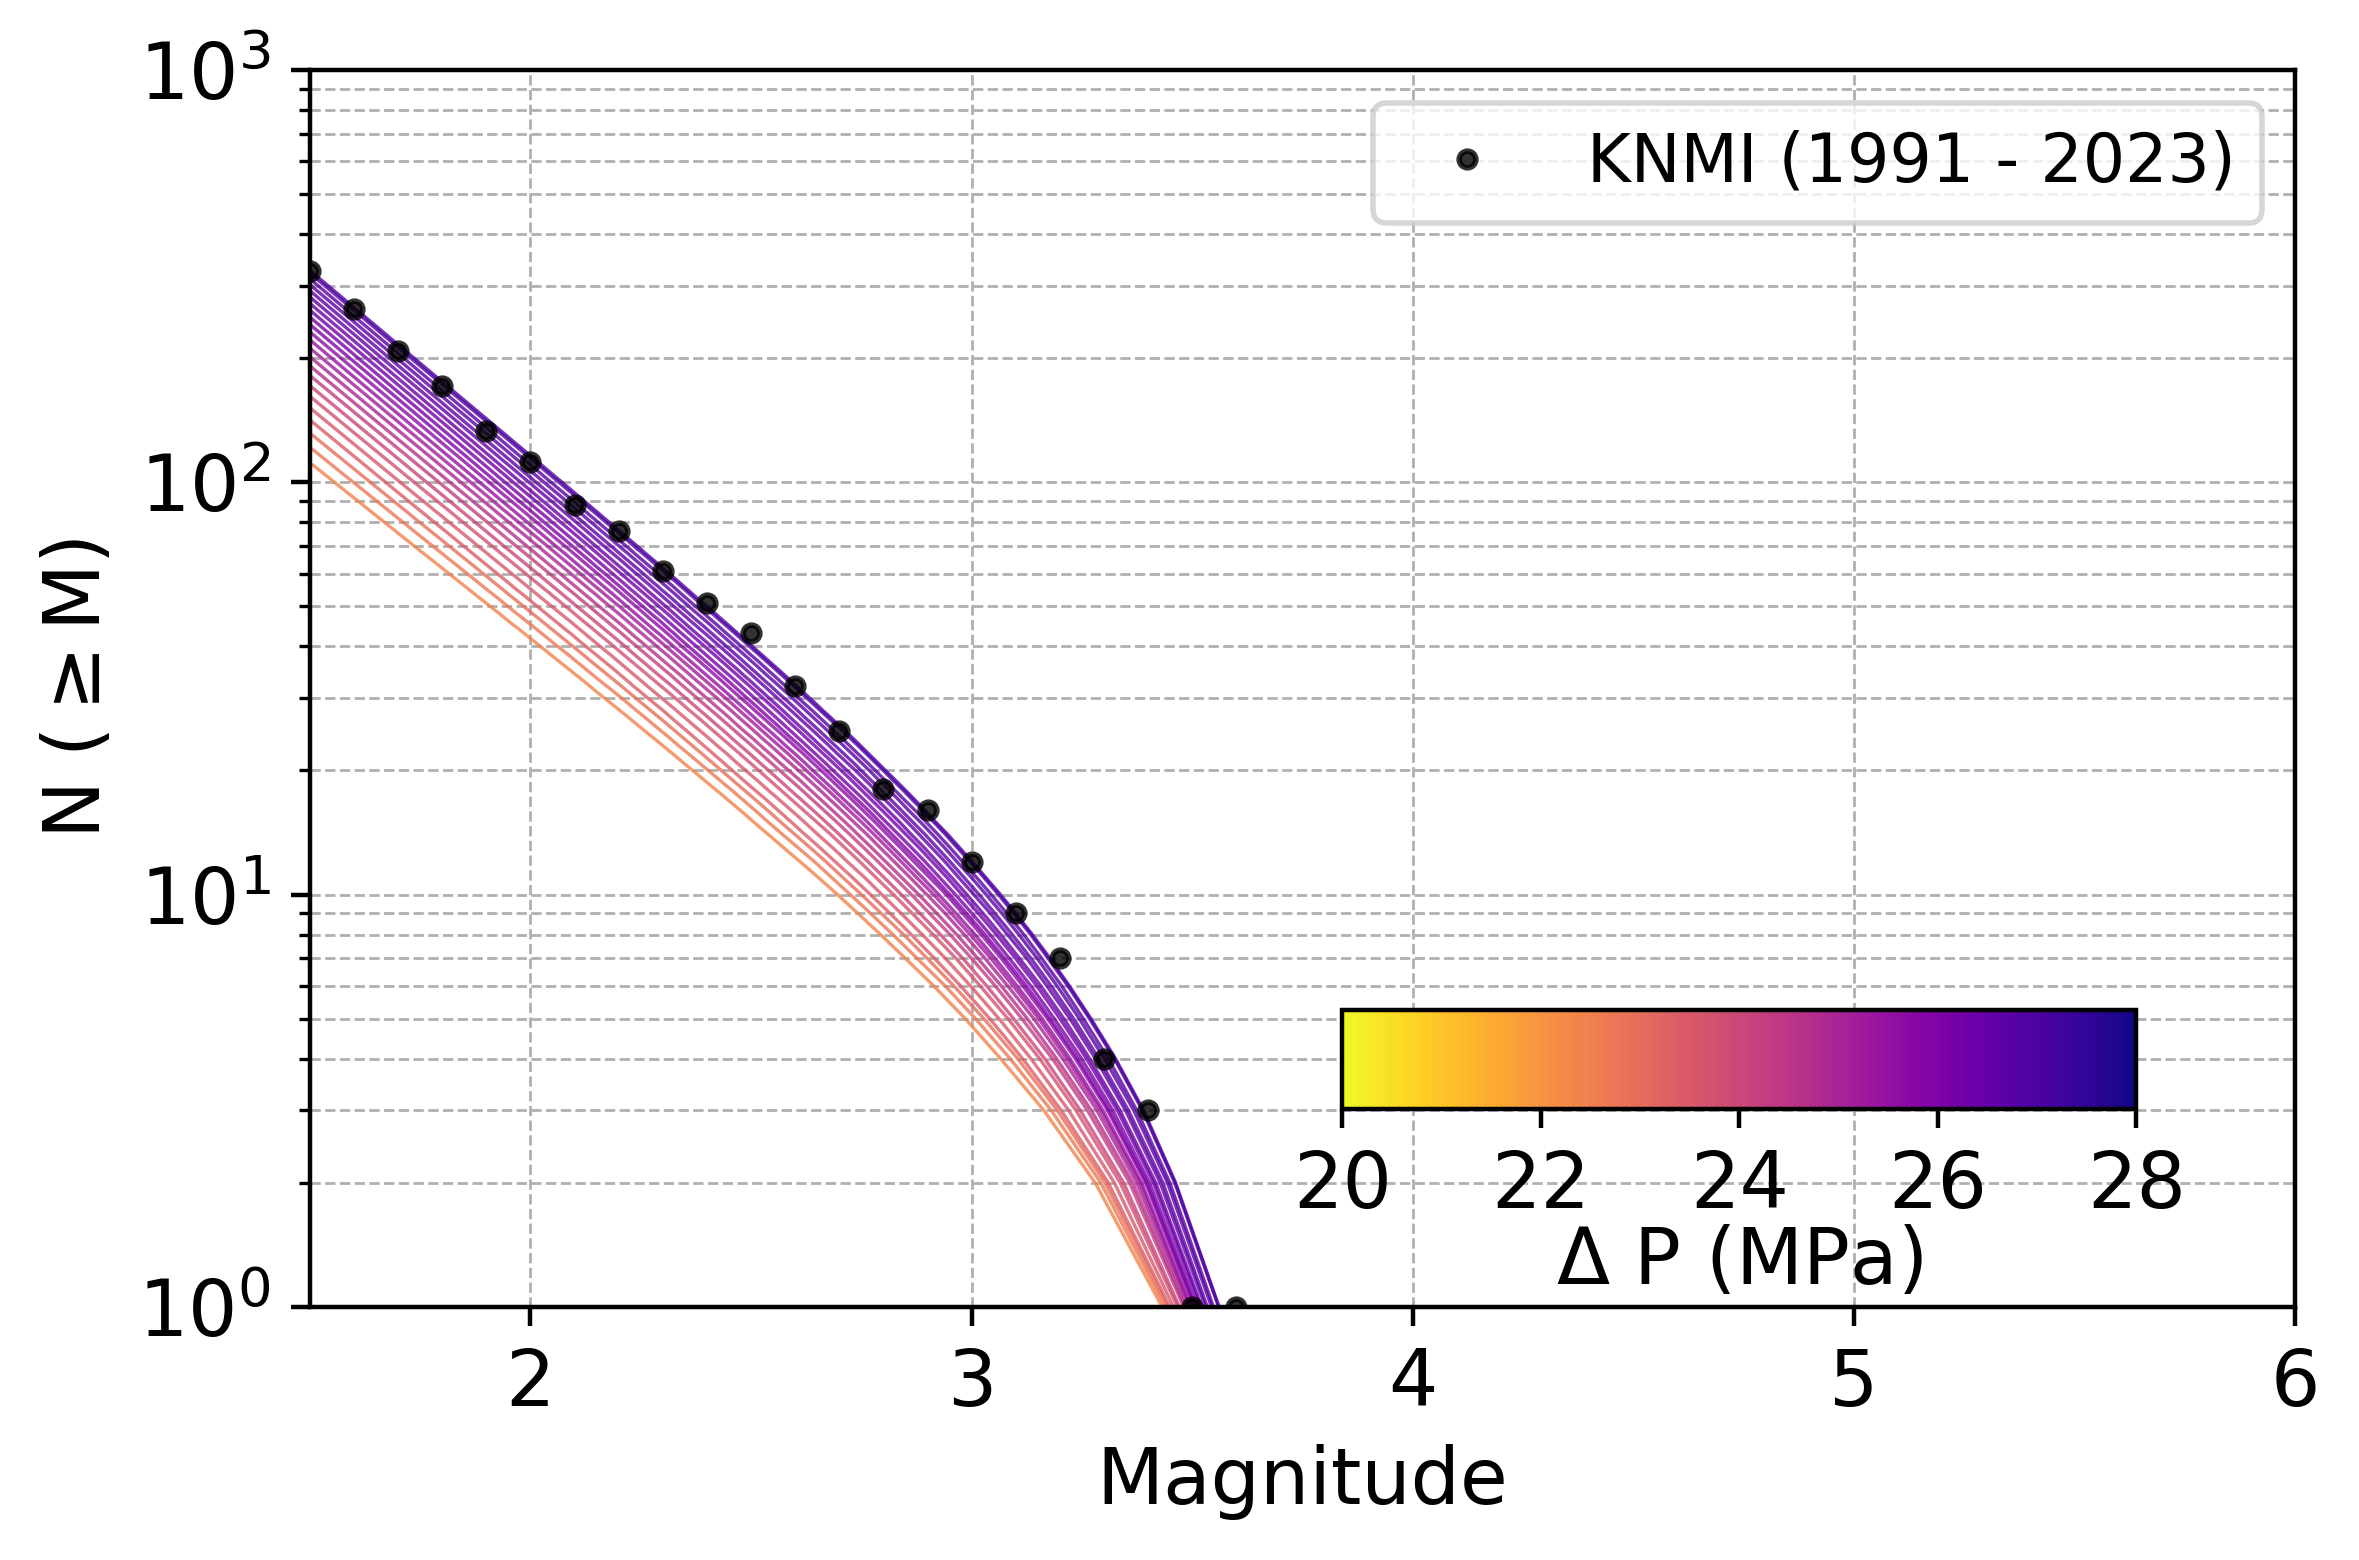

In [348]:
# Faster version of the previous cell:
# - uses float32 synthetic catalog
# - computes only median curve (the only one plotted)
# - avoids calling MFD_v2 (which also computes q05/q95)

m_syn_fast = np.asarray(m_syn, dtype=np.float32)

idx_list = np.append( np.arange(110, len(date_all), 10), len(date_all)-1 )

fig, ax = plt.subplots(figsize=(6, 4), dpi=400)

cmap = plt.get_cmap("plasma_r")

# control these directly
pad_x = 0.08   # horizontal distance from right edge of ax
pad_y = 0.16   # vertical distance from bottom edge of ax
cb_w  = 0.4  # colorbar width
cb_h  = 0.08   # colorbar height

cax = ax.inset_axes([
1 - pad_x - cb_w,  # x0
pad_y,             # y0
cb_w,              # width
cb_h               # height
])

norm = plt.Normalize(vmin = 20, vmax = 28 )
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm,cax = cax, ax=ax, orientation="horizontal", pad=0.01)
cbar.set_label(r'$\Delta$ P (MPa)', rotation=0, labelpad = 0)
cbar.set_ticks([20, 22, 24, 26, 28])

for idx in tqdm(idx_list):
    L = idx + 1
    if L < 2:
        continue

    # Sort prefix once, then take order statistics for N=1..L-1
    syn_sorted = np.sort(m_syn_fast[:, :L], axis=1)            # ascending
    mw_ranked = syn_sorted[:, 1:][:, ::-1]                     # max, 2nd max, ..., rank L-1
    mfd_median = np.median(mw_ranked, axis=0)                  # median across seeds
    centers_N = np.arange(1, L)

    # mfd_median[-1] = 1.5

    ax.plot(mfd_median, centers_N, color=sm.to_rgba(dpressure_mean_all[idx]), linewidth = 0.6, alpha = 0.8)

# KNMI catalog
ax.plot(centers_m, MFD(magnitude_all, centers_m), "k.", alpha=0.8, label="KNMI (1991 - 2023)")

ax.set_xlabel("Magnitude")
ax.set_ylabel(r"N ($\geq$M)")
ax.set_yscale("log")
ax.set_xlim(1.5, 6.0)
ax.set_ylim(1, 1000)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)
ax.legend(loc="upper right", fontsize=12)

plt.tight_layout()
plt.show()

fig.savefig(f'{output_dir}/Fig_4C.png', bbox_inches='tight', dpi = 400)

In [349]:
stop

NameError: name 'stop' is not defined

In [351]:
def float_year_to_ym(year_float):
    year = int(year_float)
    month = int(round((year_float - year) * 12)) + 1
    if month == 13:
        year += 1
        month = 1
    return f"{year:04d}/{month:02d}"

In [352]:
sub_out_dir = Path(f"{output_dir}/MFD_temporal")

if sub_out_dir.exists() and sub_out_dir.is_dir():
    # Remove files first, then empty subdirectories
    for p in sorted(sub_out_dir.rglob("*"), key=lambda x: len(x.parts), reverse=True):
        if p.is_file() or p.is_symlink():
            p.unlink()
        elif p.is_dir():
            p.rmdir()
    print("Cleared all contents in 'out'.")
else:
    print("'out' folder does not exist.")

sub_out_dir.mkdir(parents=True, exist_ok=True)
print(f"Folder ready: {sub_out_dir.resolve()}")

'out' folder does not exist.
Folder ready: /home/qshi2/Mmax_Groningen/out/Temporal_beta_const/MFD_temporal


In [353]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import os


# ============================================================
# Precompute shared arrays
# ============================================================

m_syn_fast = np.asarray(m_syn, dtype=np.float32)

# Precompute observed cumulative counts
obs_ge = magnitude_all[:, None] >= centers_m[None, :]
obs_cum_counts = np.cumsum(obs_ge, axis=0)


# ============================================================
# Worker function: generate one figure
# ============================================================

def plot_one_temporal_mfd(idx):

    L = idx + 1

    if L < 2:
        return

    # --------------------------------------------------------
    # Synthetic MFD quantiles
    # --------------------------------------------------------

    syn_prefix = m_syn_fast[:, :L]

    syn_sorted = np.sort(syn_prefix, axis=1)

    # centers_N = 1,...,L-1
    # corresponding sorted columns = L-1,...,1
    rank_cols = np.arange(L - 1, 0, -1)

    mw_ranked = syn_sorted[:, rank_cols]

    q05_arr, q50_arr, q95_arr = np.quantile(
        mw_ranked,
        [0.05, 0.50, 0.95],
        axis=0
    )

    centers_N = np.arange(1, L)


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(6, 4), dpi=400)

    ax.plot(
        q50_arr,
        centers_N,
        'b-',
        alpha=1
    )

    ax.fill_betweenx(
        centers_N,
        q05_arr,
        q95_arr,
        alpha=0.4,
        color='C0'
    )

    # Observed catalog
    ax.plot(
        centers_m,
        obs_cum_counts[idx],
        'k.',
        label=(
            f'KNMI '
            f'({float_year_to_ym(date_all[0])}-'
            f'{float_year_to_ym(date_all[idx])})'
        )
    )

    ax.set_xlabel('Magnitude')
    ax.set_ylabel(r'N ($\geq$M)')

    ax.set_yscale('log')

    ax.set_xlim(1.5, 6.0)
    ax.set_ylim(1, 1000)

    ax.grid(
        True,
        which='both',
        linestyle='--',
        linewidth=0.5
    )

    ax.legend(
        loc='upper right',
        fontsize=12
    )

    plt.tight_layout()

    fig.savefig(
        f"{sub_out_dir}/Temporal_MFD_cumulative_bin_{idx:03d}.png",
        bbox_inches='tight'
    )

    plt.close(fig)


# ============================================================
# Parallel execution
# ============================================================

n_jobs = max(1, os.cpu_count() - 1)

Parallel(
    n_jobs=n_jobs,
    backend='loky',
    verbose=0,
)(
    delayed(plot_one_temporal_mfd)(idx)
    for idx in tqdm(
        range(1, len(date_all)),
        desc='Generating MFD figures'
    )
)

/home/qshi2/anaconda3/envs/wind/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating MFD figures: 100%|██████████| 325/325 [00:07<00:00, 44.78it/s]


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,

In [354]:
# Collect all saved figures
image_files = sorted(  Path(sub_out_dir).glob( 'Temporal_MFD_cumulative_bin_*.png')  )

# Create GIF
imageio.mimsave(f'{output_dir}/Movie_MFD.gif', [imageio.imread(str(f)) for f in image_files], duration=2)

print(f"Created animation from {len(image_files)} figures")

/tmp/ipykernel_804540/4045790066.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  imageio.mimsave(f'{output_dir}/Movie_MFD.gif', [imageio.imread(str(f)) for f in image_files], duration=2)


Created animation from 325 figures


In [355]:
image_files = sorted(
    Path(sub_out_dir).glob('Temporal_MFD_cumulative_bin_*.png')
)

output_file = f'{output_dir}/Movie_MFD.mp4'

with imageio.get_writer(
    output_file,
    fps = 20, #normal - 20
    codec='libx264',
    quality=8
) as writer:

    for f in image_files:
        image = imageio.imread(f)

        # Make dimensions even if necessary
        h, w = image.shape[:2]
        image = image[:h - h % 2, :w - w % 2]

        writer.append_data(image)

print(f"Created animation from {len(image_files)} figures")

/tmp/ipykernel_804540/685840543.py:15: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(f)
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (2360, 1560) to (2368, 1568) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Created animation from 325 figures


In [356]:
stop

NameError: name 'stop' is not defined

## heatmap

In [357]:
# thickness bins
log10_thickness = np.log10(thickness_all)
bins = np.linspace(log10_thickness.min(), log10_thickness.max(), 6) # 6

# For each bin, make a list of events with thickness in that bin
events_index = []
for i in range(len(bins)-1):
    mask = (log10_thickness >= bins[i]) & (log10_thickness <= bins[i+1])
    indexs = [j for j in range(len(thickness_all)) if mask[j]]
    events_index.append(indexs)

In [358]:
Mw_bin_max_percentile = np.full( [len(seeds), len(events_index)], np.empty )

for idx, idx_Hbin in enumerate(events_index):
    m_synthetic_max_allseeds_allHbin = np.max( m_synthetic_allseeds_all[:, idx_Hbin], axis = 1)
    Mw_bin_max_percentile[:, idx] = m_synthetic_max_allseeds_allHbin


In [359]:
from matplotlib.patches import Patch

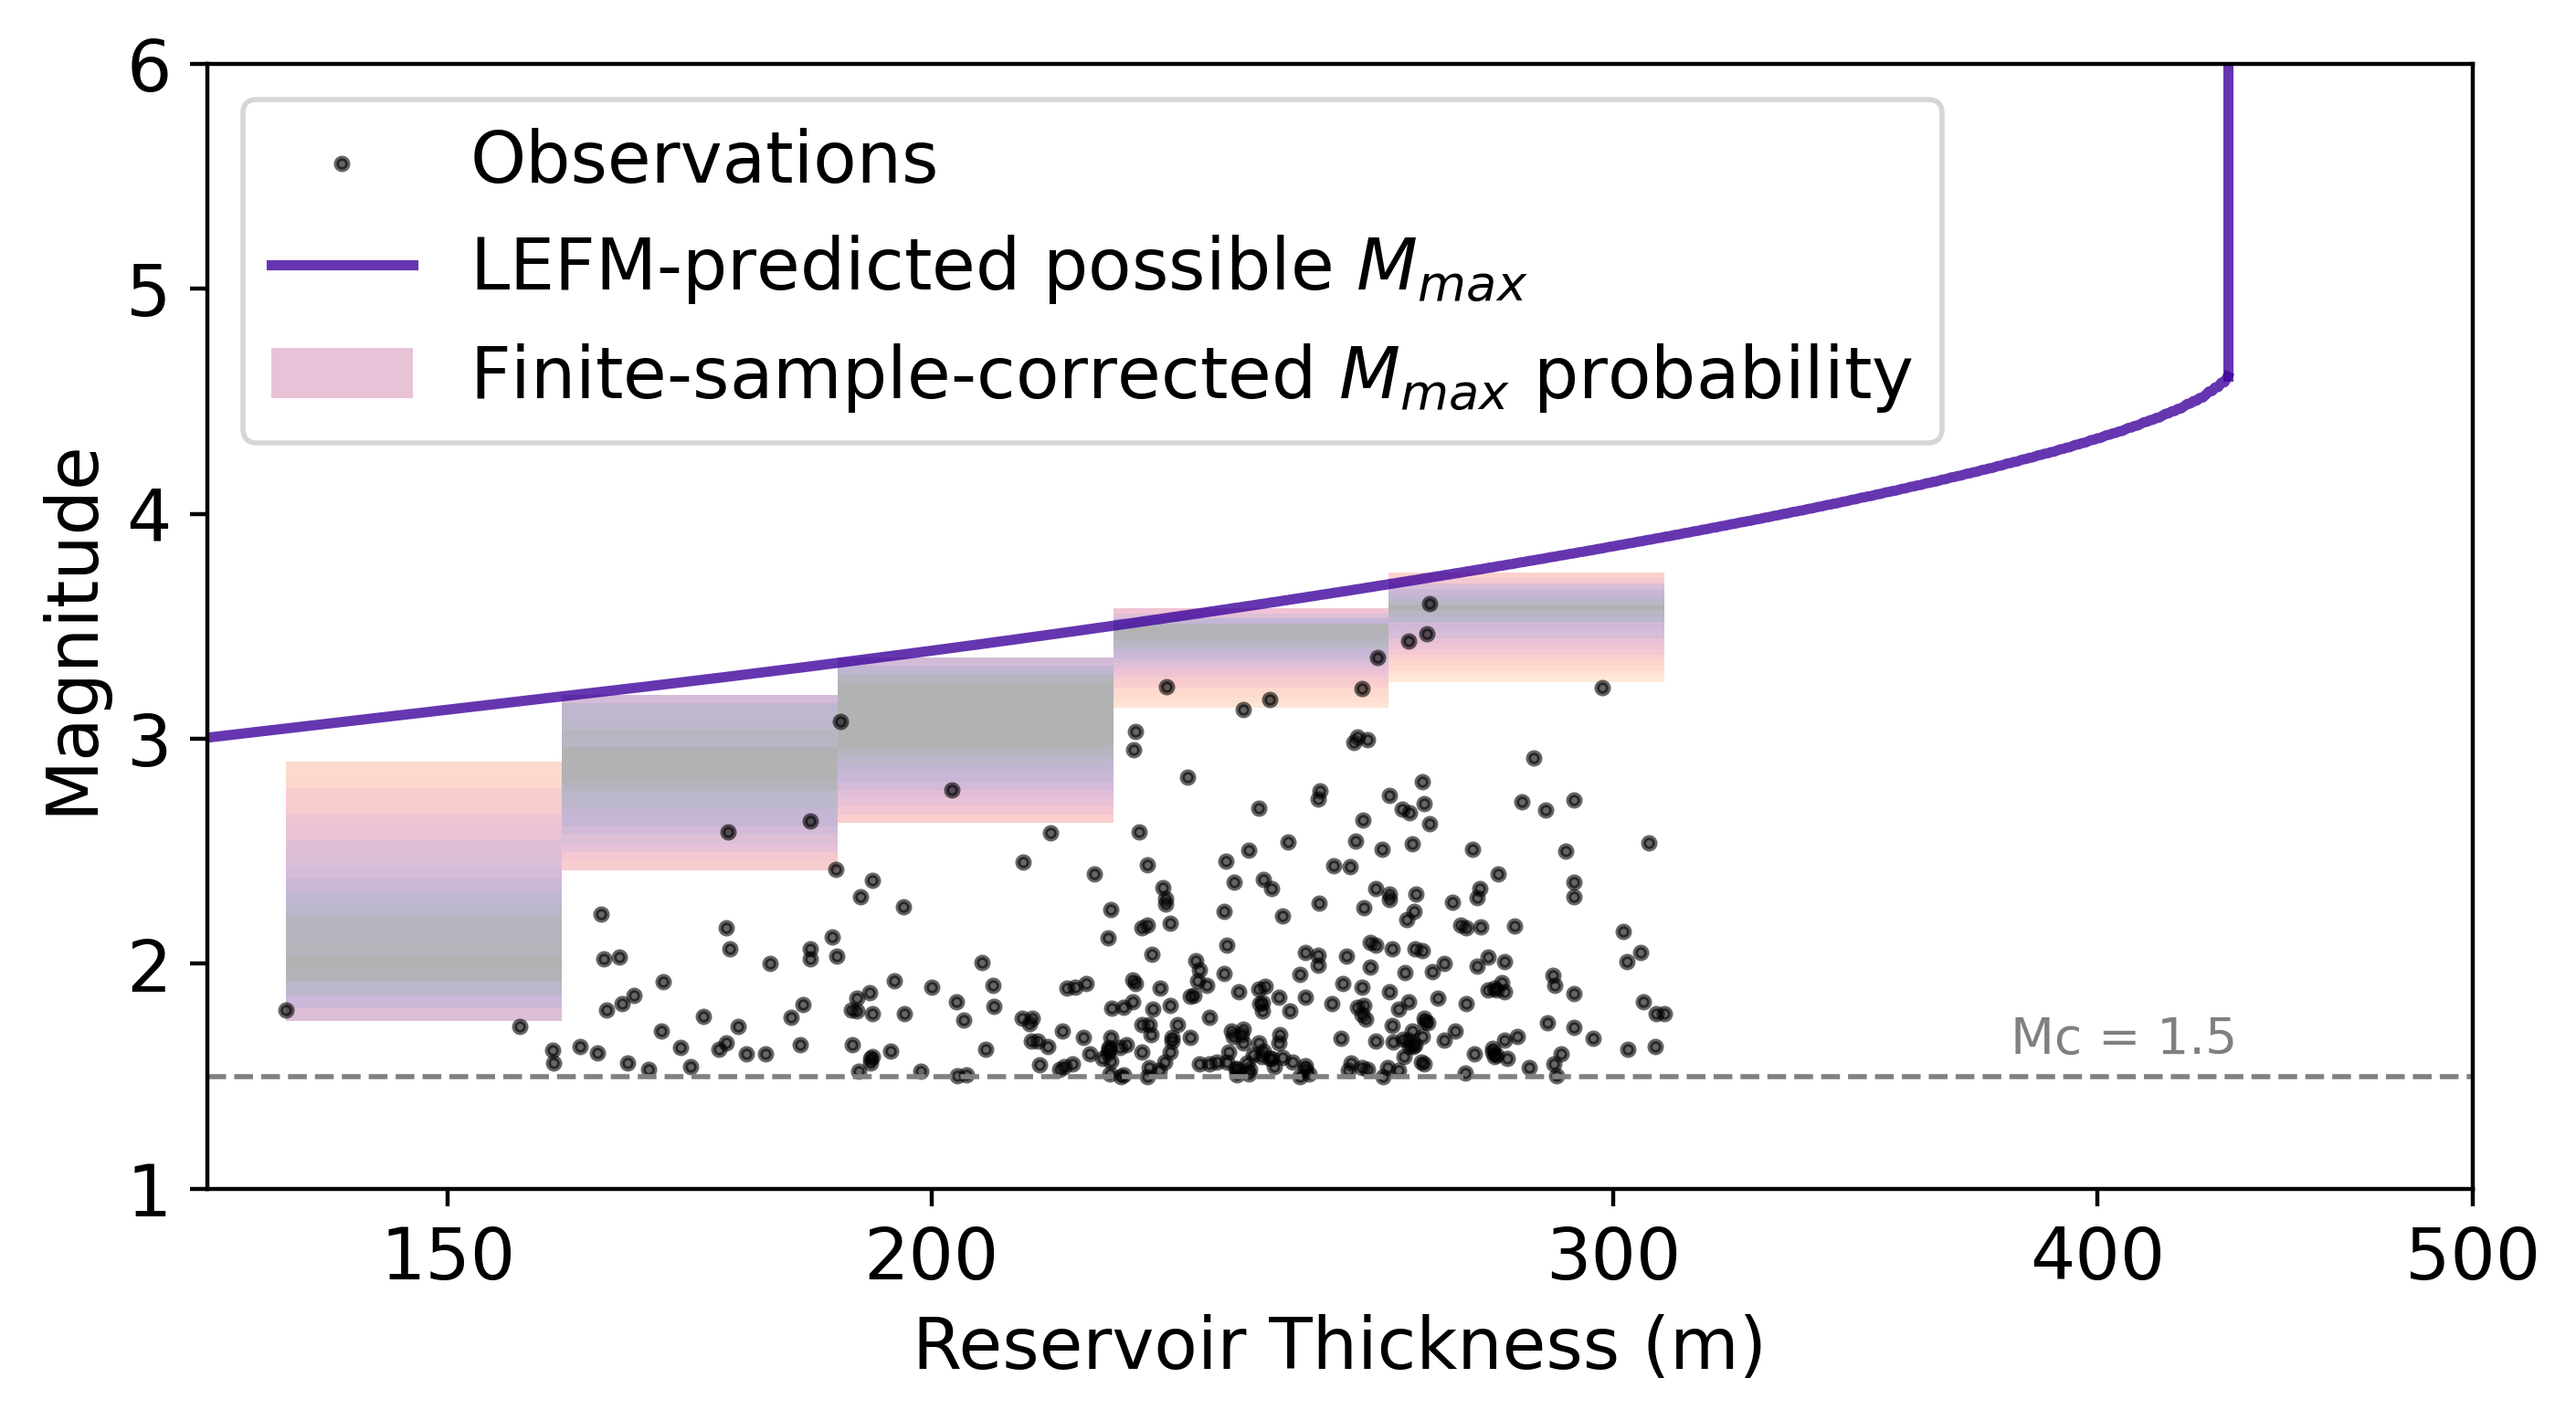

In [360]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=400)

# upper bound at closure

cmap = 'plasma_r'
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=16, vmax=28))

Mw_bound_closure = Mw_bounds_all_allHi[-1,:]
l_LEFM = ax.plot(Hi, Mw_bound_closure, color = sm.to_rgba(dpressure_mean_all[-1]), linewidth = 2, alpha = 0.8, label = r'LEFM-predicted possible $M_{max}$' )
idx_lc = np.nanargmax(Mw_bound_closure)
Hc = Hi[idx_lc]
Mcritical = Mw_bound_closure[idx_lc]
ax.plot( Hc*np.ones(20),  Mcritical + np.linspace(0, 6.0 - Mcritical, 20), color = sm.to_rgba(dpressure_mean_all[-1]), linewidth = 2, alpha = 0.8  )

# Mc
ax.axhline(y=Mc, color='gray', linestyle='--', linewidth=1)
ax.text(380, Mc + 0.1, f'Mc = {Mc}', color='gray', fontsize=10)



# For each bin, plot a heatmap of Mw_bin_max_percentile across all seeds
for idx_bin in range(len(bins)-1):
    H_local_min = 10**bins[idx_bin]
    H_local_max = 10**bins[idx_bin+1]
    
    # Get all max magnitudes for this bin across all seeds
    mw_values = Mw_bin_max_percentile[:, idx_bin]
    
    # Create a 2D histogram (heatmap) within this bin
    n_h_bins = 1
    n_mw_bins = 20
    h_edges = np.linspace(H_local_min, H_local_max, n_h_bins + 1)
    # mw_edges = np.linspace(mw_values.min() - 0.05, mw_values.max() + 0.05, n_mw_bins + 1)
    mw_edges = np.linspace(np.percentile(mw_values, 5), np.percentile(mw_values, 95), n_mw_bins + 1)
    
    # Each seed contributes a horizontal line at its Mw_max value across the bin,
    # so we spread each seed's value uniformly across all H positions in the bin
    H_tiled = np.tile(np.linspace(H_local_min, H_local_max, n_h_bins), len(mw_values))
    Mw_tiled = np.repeat(mw_values, n_h_bins)
    
    hist, xedges, yedges = np.histogram2d(H_tiled, Mw_tiled, bins=[h_edges, mw_edges])
    
    # Normalize each column to get density
    hist = hist / hist.max() if hist.max() > 0 else hist
    
    # Plot as pcolormesh
    X, Y = np.meshgrid(xedges, yedges)
    cmap = plt.get_cmap('magma_r') # plt.cm.Reds.copy()
    cmap.set_under(alpha=0)
    ax.pcolormesh(X, Y, hist.T, cmap=cmap, vmin=0.01, alpha=0.3, shading='flat'  )

# Plot mean and median lines on top
for idx_bin in range(len(bins)-1):
    thickness_bin = np.linspace(10**bins[idx_bin], 10**bins[idx_bin+1], 20)
    Mw_bin_max_mean = np.mean(Mw_bin_max_percentile[:, idx_bin]) * np.ones_like(thickness_bin)
    Mw_bin_max_median = np.median(Mw_bin_max_percentile[:, idx_bin]) * np.ones_like(thickness_bin)
    # ax.plot(thickness_bin, Mw_bin_max_mean, 'C3--', linewidth=1.5 )# , label='Mean' if idx_bin == 0 else '')
    # ax.plot(thickness_bin, Mw_bin_max_median, 'C0--', linewidth=1.5, alpha = 0.3) # slightly better than mean


# catalog
sc = ax.scatter(thickness_all, magnitude_all, s = 5, facecolor = 'k', alpha = 0.6, label = 'Observations'  )

ax.set_xscale('log' )
ax.set_xlabel('Reservoir Thickness (m)')
ax.set_ylabel('Magnitude')

ax.set_xlim(130, 500)
ax.set_ylim(1.0, 6.0)
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter('{x:.0f}'))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xticks([150, 200,  300, 400, 500 ]);

# legends
heatmap_legend = Patch(
    facecolor=plt.get_cmap('magma_r')(0.5),
    alpha=0.3,
    label='Finite-sample-corrected $M_{max}$ probability'
)

ax.legend(handles = [sc, l_LEFM[0], heatmap_legend], loc='upper left', fontsize = 14 )

fig.savefig(f'{output_dir}/Fig_3B.png', bbox_inches='tight', dpi=400)